<p class="lead">Este suplemento no tiene una clase propia. Existe porque cada unidad, a partir de la Unidad 3, informa un número —una exactitud, un área bajo una curva, un error— y el plan oficial nunca dice de dónde provienen esos números ni cuándo se les puede creer. Las diapositivas de esas unidades son un mapa; este texto es el territorio que hay bajo el número. Léelo de forma lineal una vez, ejecutando cada celda, y luego úsalo como referencia. Responde cuatro preguntas: cómo estimar el desempeño en pacientes que el modelo nunca ha visto (Secciones 1–4); qué número informar y qué significa clínicamente (Secciones 5–6); cómo las evaluaciones fallan sin que nadie lo note (Sección 7); y qué debe informarse para que otros puedan juzgar el modelo (Sección 8). La Sección 9 reúne las respuestas en una función que reutilizan las unidades posteriores.</p>

<div class="box key"><h4>Objetivos de aprendizaje</h4>
<ul class="objectives">
<li>Explicar por qué el error medido en la muestra de entrenamiento no es una estimación del error en pacientes nuevos, y definir los roles de las muestras de entrenamiento, validación y prueba.</li>
<li>Implementar a mano la validación cruzada de k particiones (k-fold), usar los divisores (splitters) de scikit-learn (estratificado, repetido, agrupado, dejar uno fuera) y explicar por qué la selección de hiperparámetros requiere validación cruzada anidada.</li>
<li>Describir el sobreajuste en términos de la descomposición sesgo–varianza y leer una curva de complejidad y una curva de aprendizaje.</li>
<li>Calcular, a partir de una matriz de confusión, la sensibilidad, la especificidad, la precisión (PPV), el NPV, el F1, la exactitud balanceada y el coeficiente de correlación de Matthews; explicar por qué la exactitud falla ante el desbalance de clases y por qué el PPV depende de la prevalencia.</li>
<li>Construir una curva ROC y una curva de precisión–sensibilidad (precision–recall) a partir de puntajes, calcular el AUC a mano, elegir un umbral de decisión a partir de los costos de los dos errores, y evaluar la calibración con un diagrama de confiabilidad y el puntaje de Brier.</li>
<li>Calcular MSE, RMSE, MAE y R² para un modelo de regresión y explicar por qué R² puede ser negativo en un conjunto de prueba.</li>
<li>Reconocer y prevenir las tres formas clásicas de fuga de datos, y usar divisiones agrupadas cuando los pacientes aportan varios registros.</li>
<li>Distinguir la validación interna de la externa y enumerar lo que la declaración TRIPOD+AI exige que contenga un informe.</li>
</ul></div>

<div class="box bridge"><h4>Cómo leer este notebook</h4>
<p>Cada celda de código es breve y está comentada. Ejecútala, lee su salida y luego lee el párrafo que la interpreta. Los ejercicios (cajas verdes) te piden modificar la celda anterior y volver a ejecutarla. Las cajas azules contienen ideas clave; las naranjas, errores frecuentes; las moradas, vínculos con las unidades que usan este material. Solo se usan <code>numpy</code>, <code>pandas</code>, <code>matplotlib</code>, <code>scipy</code> y <code>scikit-learn</code>, todas preinstaladas en Colab; no se descarga nada. El conjunto de datos recurrente es la muestra Wisconsin Diagnostic Breast Cancer de la Unidad 1 (569 aspirados, 30 características nucleares, etiqueta de biopsia);<sup class="c"><a href="#r20">[20]</a></sup> los ejemplos de regresión usan los datos de progresión de diabetes de Efron y colaboradores (442 pacientes, 10 variables basales).<sup class="c"><a href="#r21">[21]</a></sup></p></div>

In [1]:
# Configuración: bibliotecas usadas a lo largo del notebook. Las semillas aleatorias se fijan para que
# cada número citado en el texto sea reproducible.
import numpy as np, pandas as pd, matplotlib.pyplot as plt, scipy, sklearn
from sklearn import datasets

np.random.seed(0)
pd.set_option("display.width", 130); pd.set_option("display.max_columns", 14)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold"})
BLUE, ORANGE, GREEN, GREY = "#2b5d9b", "#d2691e", "#3a7d44", "#8a8a8a"
print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.4.6 | pandas 3.0.3 | scipy 1.17.1 | scikit-learn 1.9.0


## 1. Por qué la evaluación es la parte más difícil

### 1.1 La pregunta de la generalización

Un modelo supervisado es una función $f$ ajustada a una muestra de entrenamiento $\{(\mathbf{x}_i, y_i)\}_{i=1}^{n}$ extraída de una población de pacientes, y usada en pacientes que no están en la muestra. La cantidad que nos interesa es la <strong>pérdida esperada en un caso nuevo</strong>,

<div class="eq">$$\mathrm{Err} = \mathbb{E}_{(\mathbf{x}, y) \sim P}\big[L\big(y, f(\mathbf{x})\big)\big],$$
<span class="where">donde $P$ es la distribución poblacional de pacientes, $L$ es una función de pérdida (pérdida cero–uno para clasificación, error cuadrático para regresión) y la esperanza se toma sobre pacientes que el modelo nunca ha visto. Hastie, Tibshirani y Friedman lo llaman <em>error de prueba</em> o <em>error de generalización</em>.<sup class="c"><a href="#r18">[18]</a></sup></span></div>

No podemos calcular $\mathrm{Err}$ porque tenemos una muestra, no $P$. La metodología de evaluación es el problema de estimar $\mathrm{Err}$ a partir de la muestra sin engañarnos a nosotros mismos, y es más difícil que ajustar el modelo, porque el modelo se eligió para que la muestra se viera bien.

### 1.2 El error de entrenamiento no es una medición

La estimación obvia es el error en la propia muestra de entrenamiento, el <strong>error de entrenamiento</strong> (o <em>error de resustitución</em>). Está sesgado hacia abajo, tanto más cuanto más flexible es el modelo, porque los mismos datos se usaron dos veces: para elegir $f$ y para juzgarla. El caso extremo no necesita estadística: el clasificador del vecino más cercano (1-nearest-neighbour, Unidad 3) predice para un caso la etiqueta del caso de entrenamiento más cercano; en la muestra de entrenamiento el caso más cercano es el propio caso, de modo que la exactitud de entrenamiento es 100 % por construcción, sean cuales sean los datos.

In [2]:
# Exactitud de entrenamiento frente a exactitud en casos reservados, para el clasificador del vecino más cercano (1-NN).
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

cancer = datasets.load_breast_cancer(as_frame=True)
X, y = cancer.data.to_numpy(), cancer.target.to_numpy()     # y: 0 = maligno, 1 = benigno (codificación de scikit-learn)
feature_names = list(cancer.feature_names)

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
one_nn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1)).fit(X_tr, y_tr)
print(f"training cases: {len(y_tr)}, held-out cases: {len(y_te)}")
print(f"1-NN accuracy on the training sample : {one_nn.score(X_tr, y_tr):.3f}")
print(f"1-NN accuracy on the held-out sample : {one_nn.score(X_te, y_te):.3f}")

training cases: 398, held-out cases: 171
1-NN accuracy on the training sample : 1.000
1-NN accuracy on the held-out sample : 0.947


La exactitud de entrenamiento es exactamente 1.000 y no dice nada; la exactitud en los casos reservados, cercana a 0.95, es el primer número de este notebook que merece el nombre de <em>medición</em>. La diferencia es el <strong>optimismo</strong> del error de entrenamiento: máximo para 1-NN, pequeño para un modelo lineal con pocos parámetros, potencialmente total de nuevo para una red con millones de parámetros, y nunca cero.

### 1.3 Tres muestras, tres roles

En la práctica, los datos se separan en hasta tres muestras disjuntas, cada una con un rol.

| Muestra | Rol | ¿Cuántas veces se usa? |
|---|---|---|
| **Entrenamiento** | Ajustar los parámetros del modelo (los pesos, las divisiones del árbol, los vecinos almacenados) | Tantas como sea necesario |
| **Validación** (desarrollo, ajuste) | Elegir entre modelos e <em>hiperparámetros</em> —los parámetros de configuración que el algoritmo de ajuste no aprende, como $k$ en k-NN, la profundidad de un árbol, la intensidad de la regularización | Tantas como sea necesario, pero cada consulta cuesta un poco de optimismo |
| **Prueba** (reservada, evaluación) | Estimar el error de generalización del modelo final | **Una vez.** Un conjunto de prueba consultado dos veces se ha convertido en un conjunto de validación |

Las proporciones habituales son 60–20–20, 70–15–15 u 80–10–10 (entrenamiento–validación–prueba). No hay una regla universal: una mayor proporción de entrenamiento da un mejor modelo, una mayor proporción de prueba una medición más precisa (Sección 2), y con conjuntos de datos muy grandes un conjunto de prueba del 1 % ya contiene más casos que un estudio pequeño. La tercera fila de la tabla es la regla que más a menudo se rompe: si el conjunto de prueba se usa para comparar diez modelos y se informa el mejor, el número es el máximo de diez estimaciones ruidosas y está sesgado hacia arriba —los datos se usaron de nuevo dos veces, para elegir y para juzgar (la Sección 3.4 lo mide). Cuando los datos son escasos, la validación cruzada dentro de la muestra de entrenamiento cumple el rol de validación (Sección 3) y el conjunto de prueba se guarda para el final.

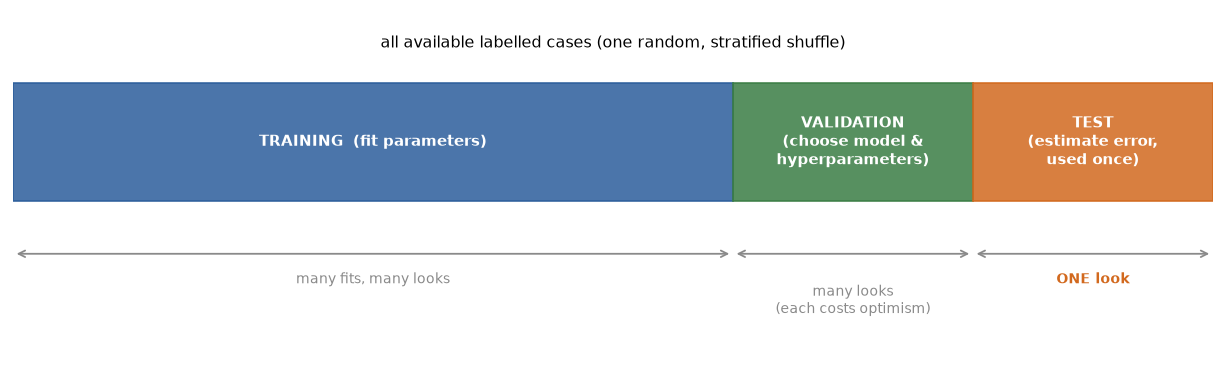

In [3]:
# Esquema de las tres muestras y sus roles.
fig, ax = plt.subplots(figsize=(9.5, 2.9))
blocks = [(0, 60, "TRAINING  (fit parameters)", BLUE), (60, 20, "VALIDATION\n(choose model &\nhyperparameters)", GREEN),
          (80, 20, "TEST\n(estimate error,\nused once)", ORANGE)]
for x0, w, lab, col in blocks:
    ax.add_patch(plt.Rectangle((x0, 1.0), w, 1.0, color=col, alpha=0.85))
    ax.text(x0 + w / 2, 1.5, lab, ha="center", va="center", color="white", fontsize=8.5, fontweight="bold")
ax.annotate("", xy=(60, 0.55), xytext=(0, 0.55), arrowprops=dict(arrowstyle="<->", color=GREY))
ax.text(30, 0.3, "many fits, many looks", ha="center", fontsize=8, color=GREY)
ax.annotate("", xy=(80, 0.55), xytext=(60, 0.55), arrowprops=dict(arrowstyle="<->", color=GREY))
ax.text(70, 0.3, "many looks\n(each costs optimism)", ha="center", va="top", fontsize=8, color=GREY)
ax.annotate("", xy=(100, 0.55), xytext=(80, 0.55), arrowprops=dict(arrowstyle="<->", color=GREY))
ax.text(90, 0.3, "ONE look", ha="center", fontsize=8, color=ORANGE, fontweight="bold")
ax.text(50, 2.3, "all available labelled cases (one random, stratified shuffle)", ha="center", fontsize=9)
ax.set_xlim(0, 100); ax.set_ylim(-0.3, 2.6); ax.axis("off")
fig.tight_layout()

<p class="caption"><b>Figura 1.</b> Las tres muestras disjuntas y sus roles. Las proporciones (aquí 60/20/20) son convencionales, no sagradas; lo que importa es que los parámetros nunca se ajusten en la muestra de validación ni en la de prueba, y que la muestra de prueba se examine una sola vez, después de haber tomado todas las decisiones.</p>

<div class="box warn"><h4>Error frecuente</h4><p>"Nuestro modelo alcanzó 99 % de exactitud" no es un resultado hasta responder tres preguntas: en qué casos (entrenamiento, validación o prueba), separados cómo (división aleatoria, por hospital, por fecha) y cuántos (un conjunto de prueba de 20 pacientes no puede distinguir 99 % de 90 %). Todo número que aparezca más adelante en este curso debe leerse con esas tres preguntas en mente.</p></div>

## 2. El método de reserva (hold-out) y su varianza

### 2.1 Una sola división es un solo sorteo

La estimación honesta más simple es el método de <strong>reserva (hold-out)</strong>: dividir al azar en una parte de entrenamiento y una parte de prueba, ajustar en la primera y evaluar en la segunda. Su debilidad es que la estimación depende de qué casos cayeron en la parte de prueba. Con $n_{\text{test}}$ casos de prueba y exactitud verdadera $p$, el número de predicciones correctas es aproximadamente binomial, de modo que

<div class="eq">$$\mathrm{SE}(\hat{p}) \approx \sqrt{\frac{\hat{p}(1-\hat{p})}{n_{\text{test}}}},$$
<span class="where">que para $\hat{p} = 0.96$ y $n_{\text{test}} = 171$ es aproximadamente 0.015: dos modelos cuyas exactitudes en reserva difieren en un punto sobre 171 casos no son distinguibles. El estudio de Kohavi de 1995 es la comparación empírica clásica entre el método de reserva, la validación cruzada y el bootstrap, y el origen de la recomendación convencional de la validación cruzada estratificada de diez particiones.<sup class="c"><a href="#r2">[2]</a></sup></span></div>

El experimento repite la división 70/30 200 veces con semillas distintas, ajustando cada vez el mismo clasificador de 5 vecinos más cercanos.

200 hold-out accuracies: mean 0.964, SD 0.013, min 0.924, max 0.988
binomial standard error predicted for n_test = 171: 0.014


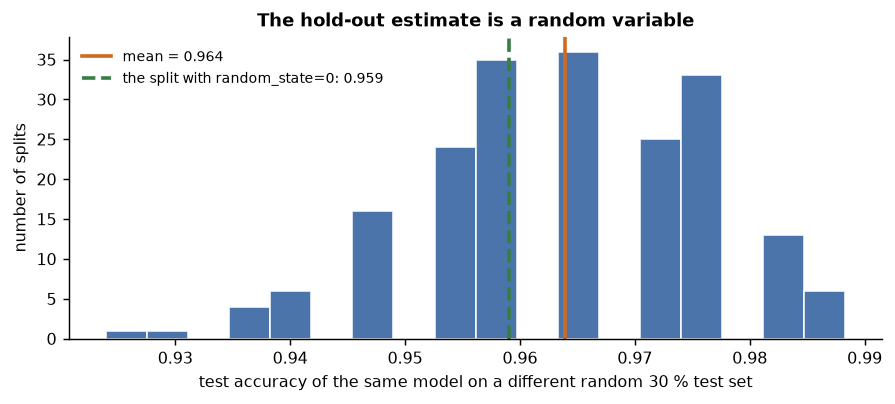

In [4]:
# Reserva repetida: 200 divisiones aleatorias 70/30 de los mismos datos con el mismo modelo (5-NN sobre características estandarizadas).
model_5nn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
accs = []
for seed in range(200):
    a, b, c, d = train_test_split(X, y, test_size=0.3, random_state=seed)   # aquí sin estratificación, a propósito
    accs.append(model_5nn.fit(a, c).score(b, d))
accs = np.array(accs)
se_binomial = np.sqrt(accs.mean() * (1 - accs.mean()) / len(y_te))
print(f"200 hold-out accuracies: mean {accs.mean():.3f}, SD {accs.std():.3f}, min {accs.min():.3f}, max {accs.max():.3f}")
print(f"binomial standard error predicted for n_test = {len(y_te)}: {se_binomial:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(accs, bins=18, color=BLUE, alpha=0.85, edgecolor="white")
ax.axvline(accs.mean(), color=ORANGE, lw=2, label=f"mean = {accs.mean():.3f}")
ax.axvline(accs[0], color=GREEN, lw=2, ls="--", label=f"the split with random_state=0: {accs[0]:.3f}")
ax.set_xlabel("test accuracy of the same model on a different random 30 % test set"); ax.set_ylabel("number of splits")
ax.legend(frameon=False, fontsize=8); ax.set_title("The hold-out estimate is a random variable")
fig.tight_layout()

<p class="caption"><b>Figura 2.</b> Distribución de la exactitud de prueba de un modelo fijo en 200 divisiones de reserva aleatorias. La dispersión (desviación estándar de aproximadamente 0.013) es tan grande como predice la fórmula binomial para 171 casos de prueba, y el rango entre la peor y la mejor división abarca varios puntos porcentuales. La línea discontinua es el único número que habría informado un notebook con <code>random_state=0</code>.</p>

Una exactitud en reserva es un sorteo de una distribución cuyo ancho está determinado por el tamaño de prueba. Informarla sin el tamaño de prueba, o comparar dos modelos en divisiones distintas, es informar ruido. De ello se siguen dos remedios: evaluar en todos los datos por rotación (validación cruzada, Sección 3) e informar un intervalo en lugar de un punto.

### 2.2 Estratificación

Una división aleatoria también puede, por azar, dejar proporciones de clases distintas en la parte de prueba y en la de entrenamiento, lo que sesga la estimación y aumenta su varianza. La división <strong>estratificada</strong> realiza la división dentro de cada clase, de modo que las proporciones se conservan. Con 569 casos el efecto es pequeño; con los tamaños muestrales de un estudio piloto clínico no lo es, y una clase puede desaparecer por completo de la parte de prueba. La celda reduce el conjunto de prueba a 20 casos para que el efecto sea visible.

In [5]:
# Estratificación: fracción de casos malignos en un conjunto de prueba de 20 casos, con y sin stratify=y, en 300 divisiones.
def malignant_fraction(stratify, n_splits=300, test_size=20):
    '''Return the fraction of malignant cases (y == 0) in the test part of n_splits random splits.'''
    out = []
    for seed in range(n_splits):
        _, _, _, d = train_test_split(X, y, test_size=test_size, random_state=seed, stratify=stratify)
        out.append(np.mean(d == 0))
    return np.array(out)

plain, strat = malignant_fraction(None), malignant_fraction(y)
tab = pd.DataFrame({"min": [plain.min(), strat.min()], "mean": [plain.mean(), strat.mean()], "max": [plain.max(), strat.max()],
                    "SD": [plain.std(), strat.std()], "splits with < 20 % malignant": [(plain < 0.2).sum(), (strat < 0.2).sum()]},
                   index=["random split", "stratified split"]).round(3)
print(f"fraction of malignant cases in the whole sample: {np.mean(y == 0):.3f}")
tab

fraction of malignant cases in the whole sample: 0.373


,min,mean,max,SD,splits with < 20 % malignant
random split,0.15,0.367,0.65,0.103,7
stratified split,0.35,0.350,0.35,0.000,0


Sin estratificación, la fracción maligna de un conjunto de prueba de 20 casos oscila entre aproximadamente 15 % y 65 % de los casos; con ella, cada división contiene el mismo número de casos malignos, de modo que las métricas por clase de la Sección 5 tienen un denominador estable. La estratificación no cuesta nada y es la opción por defecto para clasificación en este curso (<code>stratify=y</code>, <code>StratifiedKFold</code>). Para regresión, la precaución análoga es comprobar que los rangos de la variable objetivo en entrenamiento y en prueba se superpongan.

<div class="exercise"><h4>Ejercicio 1</h4><p>En la celda de reserva repetida, cambia <code>test_size</code> a 0.1 y luego a 0.5, y observa la desviación estándar de las 200 exactitudes. Un conjunto de prueba más pequeño hace más ruidosa la <em>estimación</em>; un conjunto de entrenamiento más pequeño empeora el <em>modelo</em>. ¿Cuál de los dos efectos domina en cada extremo? Esa disyuntiva es la razón por la que existe la validación cruzada.</p></div>

## 3. Validación cruzada

### 3.1 La idea

La <strong>validación cruzada de k particiones</strong> (k-fold cross-validation, CV) resuelve por rotación la disyuntiva del Ejercicio 1. La muestra se divide en $k$ particiones (folds) disjuntas de tamaño casi igual; para cada partición $j$, el modelo se ajusta en las otras $k-1$ particiones y se evalúa en la partición $j$. Cada caso se evalúa exactamente una vez, por un modelo que no lo vio. La estimación por CV es el promedio de los $k$ puntajes de las particiones,

<div class="eq">$$\widehat{\mathrm{Err}}_{\text{CV}} = \frac{1}{k} \sum_{j=1}^{k} \mathrm{Err}_j, \qquad \mathrm{Err}_j = \frac{1}{|F_j|} \sum_{i \in F_j} L\big(y_i, f^{(-j)}(\mathbf{x}_i)\big),$$
<span class="where">donde $F_j$ es el conjunto de índices de la partición $j$ y $f^{(-j)}$ el modelo ajustado sin ella. Stone formalizó el método en 1974 y demostró lo que la Sección 3.4 ilustra: los mismos datos no pueden a la vez seleccionar un modelo y evaluarlo.<sup class="c"><a href="#r1">[1]</a></sup> Lo convencional es $k = 5$ o $10$; $k = n$ corresponde a <em>dejar uno fuera</em> (leave-one-out, LOO).</span></div>

Observa qué estima la CV: cada $f^{(-j)}$ se entrena con $(k-1)/k$ de los datos, de modo que la CV estima el error del <em>procedimiento</em> con aproximadamente ese tamaño muestral, no el del modelo final ajustado con todos los datos, que se espera sea algo mejor. El número de la CV es, por tanto, ligeramente conservador —la dirección correcta en la que equivocarse.

### 3.2 Ejemplo resuelto a mano

Toma $n = 10$ casos con índices 0–9 y $k = 5$. Sin barajar, <code>KFold</code> asigna bloques consecutivos de $n/k = 2$ casos a cada partición de prueba:

| partición $j$ | índices de prueba $F_j$ | índices de entrenamiento | modelo ajustado | evaluado en |
|---|---|---|---|---|
| 1 | {0, 1} | {2, 3, 4, 5, 6, 7, 8, 9} | $f^{(-1)}$ | casos 0, 1 |
| 2 | {2, 3} | {0, 1, 4, 5, 6, 7, 8, 9} | $f^{(-2)}$ | casos 2, 3 |
| 3 | {4, 5} | {0, 1, 2, 3, 6, 7, 8, 9} | $f^{(-3)}$ | casos 4, 5 |
| 4 | {6, 7} | {0, 1, 2, 3, 4, 5, 8, 9} | $f^{(-4)}$ | casos 6, 7 |
| 5 | {8, 9} | {0, 1, 2, 3, 4, 5, 6, 7} | $f^{(-5)}$ | casos 8, 9 |

Supón que las exactitudes de las particiones son 1.0, 0.5, 1.0, 1.0 y 0.5. La exactitud de CV es su promedio, $0.80$, que aquí coincide con el agregado $8/10$ porque las particiones son de igual tamaño. Si los casos estuvieran ordenados —todos los malignos primero, como ocurre cuando un registro se exporta ordenado por diagnóstico—, las particiones sin barajar serían catastróficas; por eso se usa <code>shuffle=True</code> con un <code>random_state</code> fijo siempre que el orden de las filas pueda contener información. La celda construye las particiones con aritmética de índices de numpy, las contrasta con la tabla y aplica el procedimiento a los 569 casos de cáncer de mama.

La celda siguiente construye las mismas cinco particiones con aritmética de índices de numpy, las contrasta con la tabla y luego aplica el procedimiento hecho a mano a los 569 casos de cáncer de mama.

In [6]:
# Validación cruzada de 5 particiones a mano: solo aritmética de índices, sin divisor de scikit-learn.
def kfold_indices(n, k, rng=None):
    '''Return a list of k (train_idx, test_idx) pairs covering range(n); shuffled if an rng is given.'''
    order = np.arange(n) if rng is None else rng.permutation(n)
    folds = np.array_split(order, k)                       # k bloques casi iguales
    return [(np.setdiff1d(order, f), f) for f in folds]      # entrenamiento = todo lo que no está en la partición de prueba

# (a) el ejemplo de juguete de la tabla: n = 10, k = 5, sin barajar
for j, (tr, te) in enumerate(kfold_indices(10, 5), start=1):
    print(f"fold {j}: test {te.tolist()}  train {tr.tolist()}")

# (b) el mismo procedimiento en los datos de cáncer de mama, barajando, para el modelo 5-NN
rng = np.random.default_rng(0)
fold_acc = []
for tr, te in kfold_indices(len(y), 5, rng):
    fold_acc.append(model_5nn.fit(X[tr], y[tr]).score(X[te], y[te]))
print("\nbreast cancer, 5 folds of", [len(te) for _, te in kfold_indices(len(y), 5)], "cases")
print("fold accuracies:", np.round(fold_acc, 3), "->  CV accuracy =", f"{np.mean(fold_acc):.3f}  (SD across folds {np.std(fold_acc):.3f})")

fold 1: test [0, 1]  train [2, 3, 4, 5, 6, 7, 8, 9]
fold 2: test [2, 3]  train [0, 1, 4, 5, 6, 7, 8, 9]
fold 3: test [4, 5]  train [0, 1, 2, 3, 6, 7, 8, 9]
fold 4: test [6, 7]  train [0, 1, 2, 3, 4, 5, 8, 9]
fold 5: test [8, 9]  train [0, 1, 2, 3, 4, 5, 6, 7]

breast cancer, 5 folds of [114, 114, 114, 114, 113] cases
fold accuracies: [0.956 0.956 0.991 0.991 0.965] ->  CV accuracy = 0.972  (SD across folds 0.016)


La parte (a) reproduce exactamente la tabla. La parte (b) da una exactitud de CV de cinco particiones para 5-NN de aproximadamente 0.96–0.97, con diferencias de uno o dos puntos entre particiones —la dispersión de la Figura 2, ahora visible dentro de una sola ejecución, y en sí misma un hallazgo: un modelo cuyos puntajes por partición van de 0.80 a 0.99 es inestable.

### 3.3 Los divisores (splitters) de scikit-learn

scikit-learn<sup class="c"><a href="#r22">[22]</a></sup> implementa el ciclo como <code>cross_val_score(model, X, y, cv=...)</code>, donde <code>cv</code> es un divisor:

- <code>KFold(k, shuffle=True, random_state=0)</code> — la versión simple de la Sección 3.2; adecuada para conjuntos de datos grandes y balanceados, donde cada partición es representativa por puro tamaño. Costo: $k$ ajustes.
- <code>StratifiedKFold</code> — cada partición conserva las proporciones de clases (Sección 2.2); la opción para conjuntos de datos pequeños o desbalanceados, y la opción por defecto para clasificación en este curso. Costo: $k$ ajustes.
- <code>RepeatedStratifiedKFold(n_splits=k, n_repeats=r)</code> — el procedimiento k-fold repetido $r$ veces con distintos barajados, promediando $kr$ puntajes. Reduce la varianza debida a la partición particular (no la varianza debida a tener solo $n$ casos, que nada reduce). Costo: $kr$ ajustes.
- <code>LeaveOneOut()</code> — $k = n$: cada caso es predicho por un modelo entrenado con todos los demás. Casi insesgado para el error con tamaño $n-1$, pero cuesta $n$ ajustes y, como los $n$ conjuntos de entrenamiento son casi idénticos, su estimación tiene alta varianza;<sup class="c"><a href="#r18">[18]</a></sup> adecuado solo para conjuntos de datos muy pequeños (unas pocas decenas de casos), donde no se puede prescindir de ninguna partición.
- <code>GroupKFold</code> — los casos de un mismo grupo (paciente, hospital, serie de imágenes) nunca aparecen a la vez en particiones de entrenamiento y de prueba (Sección 7.3).
- <code>ShuffleSplit</code> — reserva repetida como en la Figura 2; los conjuntos de prueba se superponen entre repeticiones.

El tutorial de Raschka revisa estos esquemas, y las alternativas bootstrap omitidas aquí, con código resuelto.<sup class="c"><a href="#r19">[19]</a></sup> La celda los compara sobre el mismo modelo y los mismos datos, junto con el número de ajustes que cuesta cada uno.

In [7]:
# El mismo modelo evaluado con los divisores de scikit-learn; media, SD entre particiones y número de ajustes.
from sklearn.model_selection import cross_val_score, KFold, StratifiedKFold, RepeatedStratifiedKFold, LeaveOneOut, ShuffleSplit
import time

splitters = {
    "KFold(5, shuffle)":              KFold(5, shuffle=True, random_state=0),
    "StratifiedKFold(5, shuffle)":    StratifiedKFold(5, shuffle=True, random_state=0),
    "StratifiedKFold(10, shuffle)":   StratifiedKFold(10, shuffle=True, random_state=0),
    "RepeatedStratifiedKFold(5 x 10)": RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0),
    "ShuffleSplit(20 x 30 %)":        ShuffleSplit(n_splits=20, test_size=0.3, random_state=0),
    "LeaveOneOut (569 fits)":         LeaveOneOut(),
}
rows = []
for name, cv in splitters.items():
    t0 = time.time()
    s = cross_val_score(model_5nn, X, y, cv=cv)
    rows.append({"splitter": name, "mean accuracy": s.mean(), "SD across folds": s.std(), "fits": len(s), "seconds": time.time() - t0})
pd.DataFrame(rows).set_index("splitter").round(3)

,mean accuracy,SD across folds,fits,seconds
splitter,,,,
"KFold(5, shuffle)",0.965,0.011,5,0.009
"StratifiedKFold(5, shuffle)",0.965,0.021,5,0.009
"StratifiedKFold(10, shuffle)",0.965,0.025,10,0.017
RepeatedStratifiedKFold(5 x 10),0.967,0.016,50,0.084
ShuffleSplit(20 x 30 %),0.968,0.014,20,0.037
LeaveOneOut (569 fits),0.970,0.170,569,0.843


Todos los divisores coinciden en la media con una diferencia de pocas milésimas: con 569 casos y un modelo estable, la estimación no es sensible al divisor. La SD de dejar uno fuera carece de sentido como incertidumbre (cada partición es un caso puntuado 0 o 1); la columna de costo es la lista de precios —instantáneo para k-NN, decisivo para las redes de las Unidades 6 y 8, donde un ajuste puede tardar horas. La figura hace visibles los divisores: cada fila un divisor, cada columna un caso (ordenado por clase), el color la partición en que se evalúa el caso.

La figura siguiente hace visibles los divisores: cada fila es un divisor, cada columna un caso (ordenado por clase para facilitar la lectura) y el color indica en qué partición se evalúa el caso.

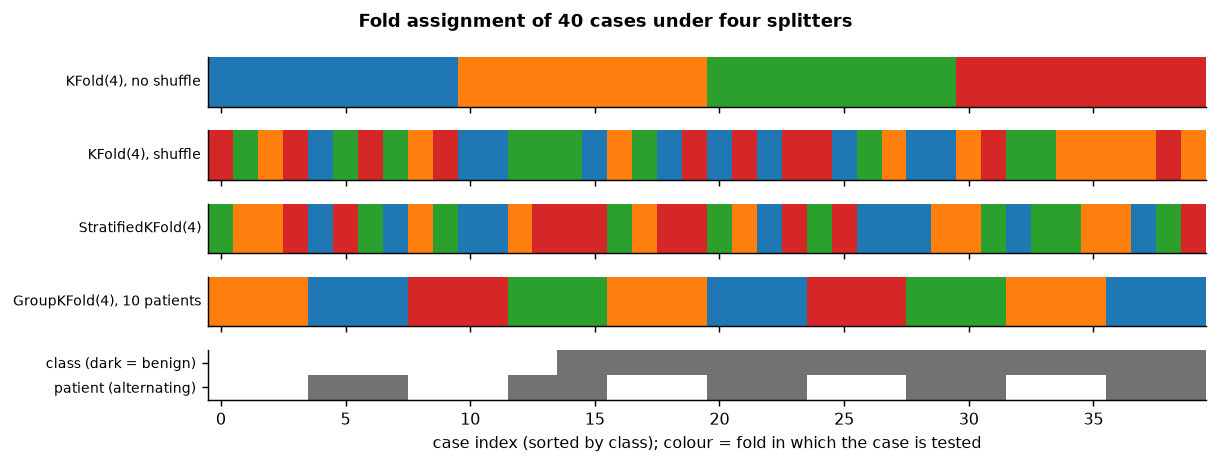

In [8]:
# ¿Qué partición evalúa qué caso? Comparación visual de tres divisores sobre una muestra pequeña ordenada.
from sklearn.model_selection import GroupKFold
rng = np.random.default_rng(0)
n_small = 40
y_small = np.r_[np.zeros(14, int), np.ones(26, int)]            # 14 'malignos', 26 'benignos', ordenados por clase
g_small = np.repeat(np.arange(10), 4)                          # 10 pacientes x 4 registros cada uno (Sección 7.3)
X_small = rng.normal(size=(n_small, 2))

schemes = {"KFold(4), no shuffle": KFold(4), "KFold(4), shuffle": KFold(4, shuffle=True, random_state=0),
           "StratifiedKFold(4)": StratifiedKFold(4, shuffle=True, random_state=0), "GroupKFold(4), 10 patients": GroupKFold(4)}
fig, axes = plt.subplots(len(schemes) + 1, 1, figsize=(9.5, 3.6), sharex=True)
for ax, (name, cv) in zip(axes, schemes.items()):
    fold_of = np.zeros(n_small, int)
    splits = cv.split(X_small, y_small, groups=g_small) if name.startswith("Group") else cv.split(X_small, y_small)
    for j, (_, te) in enumerate(splits):
        fold_of[te] = j
    ax.imshow(fold_of[None, :], cmap="tab10", vmin=0, vmax=9, aspect="auto")
    ax.set_yticks([]); ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=8)
axes[-1].imshow(np.c_[y_small, g_small % 2].T, cmap="Greys", aspect="auto", vmin=0, vmax=1.6)
axes[-1].set_yticks([0, 1]); axes[-1].set_yticklabels(["class (dark = benign)", "patient (alternating)"], fontsize=7.5)
axes[-1].set_xlabel("case index (sorted by class); colour = fold in which the case is tested")
fig.suptitle("Fold assignment of 40 cases under four splitters", fontsize=10, fontweight="bold")
fig.tight_layout()

<p class="caption"><b>Figura 3.</b> Pertenencia a particiones de 40 casos (14 malignos y luego 26 benignos) con cuatro divisores. <code>KFold</code> sin barajar pone los diez primeros casos —todos malignos— en una misma partición de prueba. <code>KFold</code> con barajado mezcla las clases, pero los recuentos por partición siguen variando. <code>StratifiedKFold</code> da a cada partición la misma composición de clases. <code>GroupKFold</code> mantiene juntos los cuatro registros de cada paciente (la fila inferior alterna el sombreado por paciente).</p>

### 3.4 Validación cruzada anidada y el optimismo de seleccionar en el conjunto de prueba

La validación cruzada es también la herramienta estándar para <strong>elegir hiperparámetros</strong>: calcular el puntaje de CV de cada configuración candidata y quedarse con la mejor. El peligro es informar ese mejor puntaje como el desempeño del modelo: es el máximo de muchas estimaciones ruidosas y está sesgado hacia arriba, tanto más cuantos más candidatos haya. Varma y Simon mostraron en conjuntos de datos genómicos pequeños que el sesgo puede superar los 20 puntos porcentuales; el remedio es la <strong>validación cruzada anidada</strong>: un ciclo externo reserva una partición de prueba y, dentro de cada conjunto de entrenamiento externo, una CV interna completa selecciona los hiperparámetros, de modo que las particiones de prueba externas nunca se usan para seleccionar.<sup class="c"><a href="#r3">[3]</a></sup> Cawley y Talbot ofrecen la teoría general.<sup class="c"><a href="#r23">[23]</a></sup>

La demostración más limpia usa datos <em>sin ninguna señal</em> —100 casos, 20 características de ruido, etiquetas aleatorias—, donde toda estimación honesta debe rondar 0.50. La celda ajusta una máquina de vectores de soporte (Unidad 3) sobre una grilla de 5 × 5 e informa (i) el mejor puntaje de CV interna, que un análisis descuidado publicaría, y (ii) la estimación anidada.

In [9]:
# Sesgo optimista de la selección de hiperparámetros, medido en ruido puro (exactitud verdadera = 0.5 por construcción).
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
grid = {"svc__C": np.logspace(-2, 2, 5), "svc__gamma": np.logspace(-3, 1, 5)}      # 25 configuraciones candidatas
rng = np.random.default_rng(0)
naive, nested = [], []
for rep in range(8):                                               # 8 conjuntos de datos de ruido independientes
    Xn, yn = rng.normal(size=(100, 20)), rng.integers(0, 2, 100)   # características y etiquetas independientes
    pipe = make_pipeline(StandardScaler(), SVC())
    inner = StratifiedKFold(5, shuffle=True, random_state=rep)
    outer = StratifiedKFold(5, shuffle=True, random_state=100 + rep)
    search = GridSearchCV(pipe, grid, cv=inner)
    naive.append(search.fit(Xn, yn).best_score_)                   # el mejor de 25 puntajes de CV interna: sesgado
    nested.append(cross_val_score(GridSearchCV(pipe, grid, cv=inner), Xn, yn, cv=outer).mean())   # honesto
res = pd.DataFrame({"best inner-CV score (naive)": naive, "nested-CV estimate": nested}).round(3)
print(res.describe().loc[["mean", "min", "max"]].round(3))
print(f"\nmean optimism of the naive number: {np.mean(naive) - np.mean(nested):+.3f}  (true accuracy is 0.500)")

      best inner-CV score (naive)  nested-CV estimate
mean                        0.574                0.52
min                         0.520                0.45
max                         0.590                0.57

mean optimism of the naive number: +0.054  (true accuracy is 0.500)


En datos donde no hay nada que aprender, el mejor de los 25 puntajes internos promedia varios puntos por encima de 0.5 —una señal fabricada enteramente por la selección—, mientras que la estimación anidada se mantiene cerca del azar. Con 100 casos el efecto es moderado; con los 20–50 casos por clase de un estudio típico de biomarcadores y una grilla de cientos de configuraciones, la cifra de 20 puntos de Varma y Simon se alcanza con facilidad, y un modelo inútil se publica como útil.<sup class="c"><a href="#r3">[3]</a></sup>

<div class="box key"><h4>Idea clave: un nivel de mirar, un nivel de reservar</h4><p>Toda decisión que se tome mirando un puntaje —qué modelo, qué hiperparámetros, qué características, qué umbral— debe tomarse con datos que luego no se usen para informar el puntaje. La CV anidada automatiza esto para los hiperparámetros; la misma lógica se aplica a la selección de características (Sección 7.1) y a la exploración manual: si probaste veinte cosas e informas la mejor, el número es optimista, y un conjunto de prueba nuevo es el único remedio.</p></div>

<div class="exercise"><h4>Ejercicio 2</h4><p>Amplía la grilla a 10 × 10 configuraciones y reduce la muestra a 50 casos: ¿el optimismo crece o disminuye? Luego reemplaza el ruido por los datos de cáncer de mama: con señal real, ¿qué tan grande es la diferencia entre el número ingenuo y el anidado?</p></div>

## 4. Sobreajuste y la disyuntiva sesgo–varianza

### 4.1 Curvas de complejidad

La <strong>complejidad</strong> de un modelo es, a grandes rasgos, el número de parámetros libres que puede ajustar: el grado de un polinomio (el grado $d$ tiene $d+1$ coeficientes), la profundidad de un árbol, el número de pesos de una red. Un modelo presenta <strong>subajuste</strong> cuando es demasiado simple para representar la regularidad de los datos —una recta trazada a través de una relación curva— y se desempeña mal tanto en los datos de entrenamiento como en los de prueba. Presenta <strong>sobreajuste</strong> cuando es lo bastante complejo para reproducir los accidentes de la muestra de entrenamiento —ruido en las etiquetas, correlaciones casuales— en lugar de la regularidad; su señal característica es una brecha creciente entre el desempeño de entrenamiento y el de los casos reservados a medida que aumenta la flexibilidad. En k vecinos más cercanos (Unidad 3) la flexibilidad la fija $k$: $k = 1$ sigue individualmente cada caso de entrenamiento, $k = n$ predice la clase mayoritaria para todos. La celda recorre $k$ y registra la exactitud de entrenamiento y la de CV de diez particiones.

best k by CV: 9  (CV accuracy 0.968); at k = 1: train 1.000 / CV 0.953; at k = 301: train 0.859 / CV 0.828


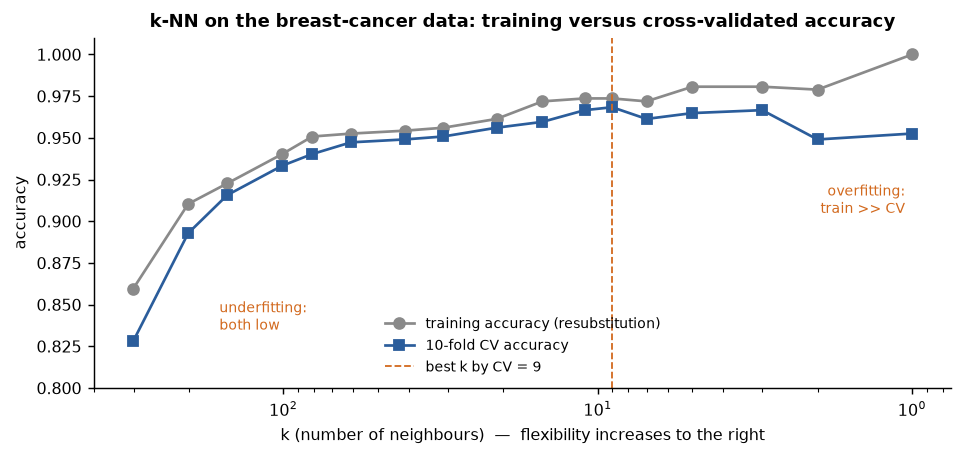

In [10]:
# Curva de complejidad: exactitud de entrenamiento y exactitud de validación cruzada de k-NN en función de k.
ks = [1, 2, 3, 5, 7, 9, 11, 15, 21, 31, 41, 61, 81, 101, 151, 201, 301]
cv10 = StratifiedKFold(10, shuffle=True, random_state=0)
train_acc, cv_acc = [], []
for k in ks:
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    train_acc.append(m.fit(X, y).score(X, y))
    cv_acc.append(cross_val_score(m, X, y, cv=cv10).mean())
best = ks[int(np.argmax(cv_acc))]
print(f"best k by CV: {best}  (CV accuracy {max(cv_acc):.3f}); at k = 1: train {train_acc[0]:.3f} / CV {cv_acc[0]:.3f}; at k = 301: train {train_acc[-1]:.3f} / CV {cv_acc[-1]:.3f}")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(ks, train_acc, "o-", color=GREY, label="training accuracy (resubstitution)")
ax.plot(ks, cv_acc, "s-", color=BLUE, label="10-fold CV accuracy")
ax.axvline(best, color=ORANGE, ls="--", lw=1, label=f"best k by CV = {best}")
ax.set_xscale("log"); ax.invert_xaxis()
ax.set_xlabel("k (number of neighbours)  —  flexibility increases to the right"); ax.set_ylabel("accuracy")
ax.set_ylim(0.80, 1.01)
ax.text(1.05, 0.905, "overfitting:\ntrain >> CV", fontsize=8, ha="right", color=ORANGE)
ax.text(160, 0.835, "underfitting:\nboth low", fontsize=8, ha="left", color=ORANGE)
ax.legend(frameon=False, fontsize=8, loc="lower center"); ax.set_title("k-NN on the breast-cancer data: training versus cross-validated accuracy")
fig.tight_layout()

<p class="caption"><b>Figura 4.</b> Exactitud de entrenamiento y de validación cruzada de k-NN en función de $k$ (la flexibilidad aumenta hacia la derecha). En el borde derecho la exactitud de entrenamiento es 1.000 y la de CV es menor: el modelo memoriza. En el borde izquierdo ambas caen juntas hacia la tasa de la clase mayoritaria, 0.627 (357 benignos de 569): subajuste. La curva de CV alcanza su máximo entre ambos extremos, en un $k$ de aproximadamente 5–15, donde las curvas están próximas. La curva de entrenamiento es monótona y no informativa; solo la curva de CV puede localizar el óptimo.</p>

### 4.2 Curvas de aprendizaje

Un segundo diagnóstico grafica el desempeño en función del <em>tamaño de la muestra de entrenamiento</em>. El puntaje de entrenamiento baja a medida que $n$ crece (una muestra más grande es más difícil de memorizar) y el puntaje de validación sube (hay más de qué aprender). La brecha en el mayor $n$ es la varianza restante; el nivel al que convergen las curvas es el sesgo restante. Una curva de aprendizaje responde la pregunta más cara del trabajo aplicado —¿ayudaría reclutar más pacientes?— antes de reclutarlos.

logistic regression (Unit 2)   at n = 512: train 0.988, CV 0.977, gap 0.011
1-nearest neighbour            at n = 512: train 1.000, CV 0.953, gap 0.047


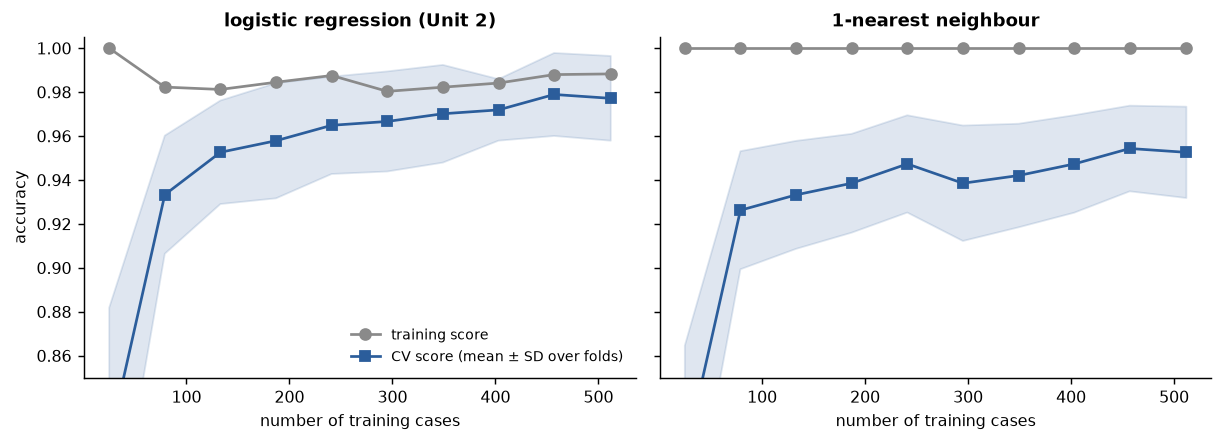

In [11]:
# Curvas de aprendizaje de dos modelos de distinta flexibilidad: puntaje de entrenamiento y de CV según el tamaño del conjunto de entrenamiento.
from sklearn.model_selection import learning_curve
from sklearn.linear_model import LogisticRegression
models = {"logistic regression (Unit 2)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
          "1-nearest neighbour": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1))}
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.5), sharey=True)
for ax, (name, m) in zip(axes, models.items()):
    sizes, tr, va = learning_curve(m, X, y, train_sizes=np.linspace(0.05, 1.0, 10), cv=cv10, random_state=0)
    ax.plot(sizes, tr.mean(1), "o-", color=GREY, label="training score")
    ax.fill_between(sizes, va.mean(1) - va.std(1), va.mean(1) + va.std(1), color=BLUE, alpha=0.15)
    ax.plot(sizes, va.mean(1), "s-", color=BLUE, label="CV score (mean ± SD over folds)")
    ax.set_title(name); ax.set_xlabel("number of training cases"); ax.set_ylim(0.85, 1.005)
    print(f"{name:30s} at n = {sizes[-1]}: train {tr.mean(1)[-1]:.3f}, CV {va.mean(1)[-1]:.3f}, gap {tr.mean(1)[-1] - va.mean(1)[-1]:.3f}")
axes[0].set_ylabel("accuracy"); axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()

<p class="caption"><b>Figura 5.</b> Curvas de aprendizaje. Izquierda: regresión logística, cuyas curvas de entrenamiento y de CV convergen hasta quedar a aproximadamente un punto de distancia con el tamaño completo —un modelo de baja varianza que ha extraído la mayor parte de lo que contienen estos datos, de modo que más pacientes ayudarían poco. Derecha: 1-NN, cuyo puntaje de entrenamiento se mantiene en 1.000 mientras el puntaje de CV se estanca por debajo —una brecha persistente que más datos reducen solo lentamente. La banda es la dispersión entre particiones.</p>

### 4.3 La descomposición sesgo–varianza

Ambos diagnósticos tienen una misma teoría detrás. Para un problema de regresión $y = f(x) + \varepsilon$ con varianza del ruido $\sigma^2$ y un procedimiento que entrega $\hat{f}_D(x)$ a partir de una muestra de entrenamiento $D$, el error cuadrático esperado en $x$, sobre las muestras y sobre el ruido de una nueva observación, se descompone exactamente como

<div class="eq">$$\mathbb{E}\big[(y - \hat{f}_D(x))^2\big] = \underbrace{\big(f(x) - \mathbb{E}_D[\hat{f}_D(x)]\big)^2}_{\text{bias}^2} + \underbrace{\mathbb{E}_D\big[(\hat{f}_D(x) - \mathbb{E}_D[\hat{f}_D(x)])^2\big]}_{\text{variance}} + \underbrace{\sigma^2}_{\text{irreducible noise}},$$
<span class="where">donde $\mathbb{E}_D$ se toma sobre las muestras de entrenamiento. El <strong>sesgo</strong> es el error que proviene de supuestos erróneos del modelo —una recta supuesta donde la realidad es curva—; es el error sistemático del ajuste promedio, grande en los modelos rígidos, y un sesgo alto produce <em>subajuste</em>. La <strong>varianza</strong> es la sensibilidad del ajuste a pequeñas fluctuaciones del conjunto de entrenamiento; es grande en los modelos flexibles, y una varianza alta produce <em>sobreajuste</em>. El término de ruido es el piso por debajo del cual ningún modelo llega. La descomposición proviene del análisis de redes neuronales de Geman, Bienenstock y Doursat de 1992;<sup class="c"><a href="#r15">[15]</a></sup> el capítulo 7 de Hastie, Tibshirani y Friedman la desarrolla para los métodos de este curso.<sup class="c"><a href="#r18">[18]</a></sup></span></div>

Más flexibilidad reduce el sesgo y aumenta la varianza; el error de prueba, su suma más el ruido, tiene forma de U, y su mínimo corresponde a la complejidad adecuada. La Figura 4 era esta forma de U vista a través de la exactitud de CV. La descomposición no puede calcularse en datos reales —$f$ es desconocida y solo existe una muestra—, pero sí simularse: 300 muestras de entrenamiento de 20 puntos de $y = \sin(2\pi x) + \varepsilon$, $\sigma = 0.3$, un polinomio de cada grado ajustado a cada muestra, y sesgo² y varianza medidos sobre los 300 ajustes.

In [12]:
# Simulación sesgo-varianza: 300 muestras de entrenamiento, ajustes polinomiales de grado 0-12 a y = sin(2 pi x) + ruido.
rng = np.random.default_rng(0)
f_true = lambda x: np.sin(2 * np.pi * x)
n_pts, sigma, R = 20, 0.3, 300
x_fixed = np.linspace(0, 1, n_pts)                      # diseño fijo: los mismos x en cada muestra, solo cambia el ruido
Y = f_true(x_fixed) + rng.normal(0, sigma, (R, n_pts))  # R muestras de entrenamiento
degrees = range(0, 13)
fits = {}                                               # grado -> matriz (R x n_pts) de curvas ajustadas
for deg in degrees:
    fits[deg] = np.array([np.polyval(np.polyfit(x_fixed, Y[r], deg), x_fixed) for r in range(R)])
decomp = pd.DataFrame({
    "bias^2":   [((fits[d].mean(0) - f_true(x_fixed)) ** 2).mean() for d in degrees],
    "variance": [fits[d].var(0).mean() for d in degrees],
}, index=pd.Index(degrees, name="degree"))
decomp["noise"] = sigma ** 2
decomp["bias^2 + variance + noise"] = decomp.sum(axis=1)
# comprobación empírica: error cuadrático de cada ajuste frente a una muestra ruidosa NUEVA
decomp["empirical test MSE"] = [((fits[d] - (f_true(x_fixed) + rng.normal(0, sigma, (R, n_pts)))) ** 2).mean() for d in degrees]
decomp.round(4).iloc[[0, 1, 2, 3, 4, 6, 9, 12]]

,bias^2,variance,noise,bias^2 + variance + noise,empirical test MSE
degree,,,,,
0,0.4750,0.0048,0.09,0.5698,0.5792
1,0.2313,0.0085,0.09,0.3298,0.3306
2,0.2313,0.0130,0.09,0.3343,0.3287
3,0.0061,0.0180,0.09,0.1140,0.1127
4,0.0061,0.0218,0.09,0.1178,0.1225
6,0.0001,0.0315,0.09,0.1216,0.1214
9,0.0001,0.0447,0.09,0.1348,0.1324
12,0.0001,0.0574,0.09,0.1475,0.1454


La tabla es la descomposición, grado por grado. En el grado 0 (una recta horizontal) el sesgo² es grande y la varianza diminuta; en el grado 3 el sesgo² casi ha desaparecido, porque una cúbica sigue de cerca un período de una sinusoide; de ahí en adelante la varianza crece con cada coeficiente mientras el sesgo² se mantiene cerca de cero. La columna "bias² + variance + noise" coincide con el error cuadrático medio frente a observaciones ruidosas nuevas dentro del error de simulación: la identidad se cumple. La figura muestra lo mismo en forma de curvas.

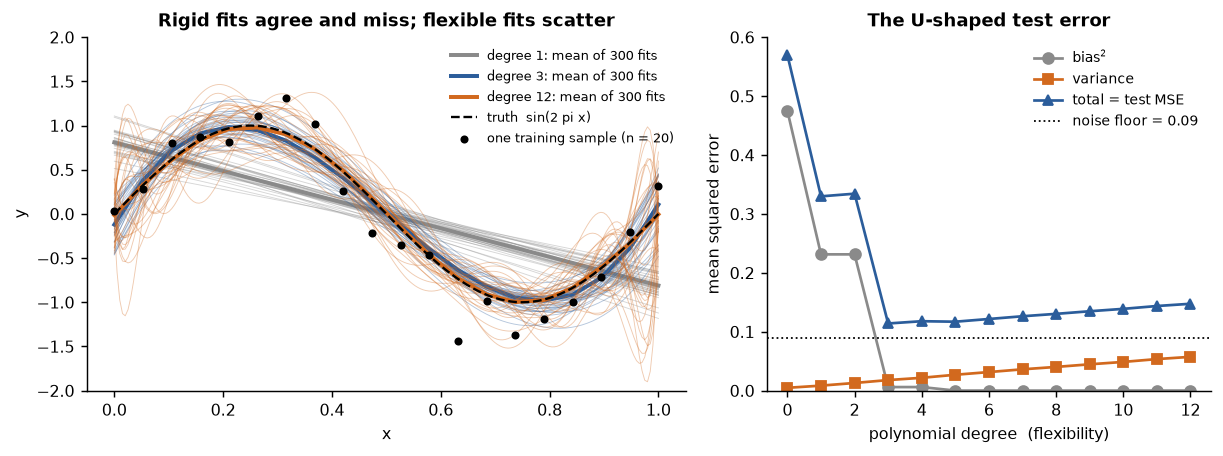

In [13]:
# Izquierda: 30 de los 300 ajustes para tres grados (líneas finas), su media (gruesa) y la verdad (discontinua).
# Derecha: la descomposición en función del grado.
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6), gridspec_kw={"width_ratios": [1.35, 1]})
xg = np.linspace(0, 1, 200)
for deg, col, off in [(1, GREY, 0), (3, BLUE, 0), (12, ORANGE, 0)]:
    for r in range(30):
        axes[0].plot(xg, np.polyval(np.polyfit(x_fixed, Y[r], deg), xg), color=col, lw=0.5, alpha=0.35)
    axes[0].plot(x_fixed, fits[deg].mean(0), color=col, lw=2.2, label=f"degree {deg}: mean of 300 fits")
axes[0].plot(xg, f_true(xg), "k--", lw=1.3, label="truth  sin(2 pi x)")
axes[0].scatter(x_fixed, Y[0], color="k", s=12, zorder=5, label="one training sample (n = 20)")
axes[0].set_ylim(-2, 2); axes[0].set_xlabel("x"); axes[0].set_ylabel("y"); axes[0].legend(frameon=False, fontsize=7.2, loc="upper right")
axes[0].set_title("Rigid fits agree and miss; flexible fits scatter")
axes[1].plot(decomp.index, decomp["bias^2"], "o-", color=GREY, label="bias$^2$")
axes[1].plot(decomp.index, decomp["variance"], "s-", color=ORANGE, label="variance")
axes[1].plot(decomp.index, decomp["bias^2 + variance + noise"], "^-", color=BLUE, label="total = test MSE")
axes[1].axhline(sigma ** 2, color="k", ls=":", lw=1, label=f"noise floor = {sigma**2:.2f}")
axes[1].set_xlabel("polynomial degree  (flexibility)"); axes[1].set_ylabel("mean squared error"); axes[1].set_ylim(0, 0.6)
axes[1].legend(frameon=False, fontsize=7.5); axes[1].set_title("The U-shaped test error")
fig.tight_layout()

<p class="caption"><b>Figura 6.</b> Izquierda: treinta ajustes de cada grado a treinta muestras de entrenamiento. Las rectas (grado 1) coinciden entre sí y todas yerran la sinusoide: sesgo puro. Las curvas de grado 12 siguen la realidad en promedio, pero cada una divaga: varianza pura. Las cúbicas cumplen ambas tareas de forma adecuada. Derecha: el sesgo² baja y la varianza sube con el grado; su suma es mínima en los grados 3–5 y nunca alcanza el piso de ruido $\sigma^2 = 0.09$.</p>

<div class="box bridge"><h4>Puente hacia las unidades</h4><p>Cada método del curso tiene una perilla sobre esta curva: $k$ en k-NN y el ancho del kernel de una SVM (Unidad 3), la profundidad de los árboles y el número de árboles (Unidad 4), las capas y la regularización de una red (Unidades 6 y 8), el grado o la penalización de una regresión (Unidad 2). La perilla se ajusta <em>siempre</em> con datos de validación o con validación cruzada, nunca con el puntaje de entrenamiento, que solo premia la flexibilidad.</p></div>

<div class="exercise"><h4>Ejercicio 3</h4><p>Cambia <code>n_pts</code> de 20 a 100 en la simulación y vuelve a ejecutar ambas celdas. La curva de varianza se aplana y el grado óptimo se desplaza hacia la derecha: con más datos, un modelo más flexible se vuelve asequible. Luego fija <code>sigma = 0.6</code>. ¿Qué ocurre con el piso de ruido y con el grado en que el error total es mínimo?</p></div>

### 4.4 La maldición de la dimensionalidad y la razón parámetros/observaciones

La complejidad también crece con el número de características. Cada característica añade un parámetro a un modelo lineal y una dimensión al espacio en que k-NN mide distancias, y en dimensiones altas una muestra fija se vuelve dispersa: cada caso está lejos de todos los demás y los vecinos "más cercanos" ya no están cerca —la <strong>maldición de la dimensionalidad</strong> (curse of dimensionality).<sup class="c"><a href="#r18">[18]</a></sup> La medida práctica es la razón parámetros/observaciones $p/n$. Con $p \geq n$, un modelo lineal puede ajustar perfectamente cualquier conjunto de etiquetas, de modo que su puntaje de entrenamiento pierde sentido; una regla práctica para los modelos de predicción clínica exige al menos diez a veinte eventos por parámetro candidato.<sup class="c"><a href="#r27">[27]</a></sup> La celda añade características de ruido puro a las 30 reales.

In [14]:
# Maldición de la dimensionalidad: se añaden características de ruido a las 30 reales (n = 569 fijo); exactitud de entrenamiento frente a CV.
rng = np.random.default_rng(0)
rows = []
for p_noise in [0, 30, 100, 300, 1000, 3000]:
    X_p = np.c_[X, rng.normal(size=(len(y), p_noise))]
    for name, m in {"5-NN": make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
                    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))}.items():
        rows.append({"noise features added": p_noise, "p / n": round(X_p.shape[1] / len(y), 2), "model": name,
                     "training accuracy": m.fit(X_p, y).score(X_p, y), "10-fold CV accuracy": cross_val_score(m, X_p, y, cv=cv10).mean()})
curse = pd.DataFrame(rows).pivot(index=["noise features added", "p / n"], columns="model", values=["training accuracy", "10-fold CV accuracy"]).round(3)
curse

training accuracy                     10-fold CV accuracy                    
model                                   5-NN logistic regression                5-NN logistic regression
noise features added p / n                                                                              
0                    0.05              0.981               0.988               0.965               0.977
30                   0.11              0.960               0.998               0.939               0.958
100                  0.23              0.956               1.000               0.928               0.963
300                  0.58              0.926               1.000               0.882               0.954
1000                 1.81              0.873               1.000               0.803               0.917
3000                 5.33              0.837               1.000               0.770               0.889

La información es idéntica en todas las filas —las mismas 30 características reales— y solo se añadieron columnas inútiles. Cuando $p/n$ supera 1, la exactitud de entrenamiento de la regresión logística llega a 1.000 (ahora puede separar cualquier asignación de etiquetas) mientras su exactitud de CV disminuye; en k-NN ambos puntajes caen, porque las distancias pasan a estar dominadas por el ruido. La selección de características y la regularización (Unidades 2–4) existen para combatir esto, y deben a su vez someterse a validación cruzada (Sección 7.1).

## 5. Métricas para clasificación

### 5.1 La matriz de confusión

Toda métrica de un clasificador binario es función de cuatro recuentos. Fija qué clase es la <strong>positiva</strong> —en medicina, la condición que se busca detectar— y cruza la clase verdadera con la predicha:

| | predicho positivo | predicho negativo | |
|---|---|---|---|
| **realmente positivo** | TP (verdadero positivo) | FN (falso negativo, <em>caso no detectado</em>) | $P = \mathrm{TP} + \mathrm{FN}$ |
| **realmente negativo** | FP (falso positivo, <em>falsa alarma</em>) | TN (verdadero negativo) | $N = \mathrm{FP} + \mathrm{TN}$ |

A partir de ellos, las métricas que usa el curso, con los nombres del aprendizaje automático y los clínicos lado a lado (las notas de Altman y Bland en el BMJ siguen siendo la explicación breve más clara del vocabulario clínico<sup class="c"><a href="#r16">[16]</a>,<a href="#r17">[17]</a></sup>):

| Métrica | Fórmula | Nombre clínico | Se lee como |
|---|---|---|---|
| Exactitud (accuracy) | $(\mathrm{TP}+\mathrm{TN})/(P+N)$ | — | fracción de todos los casos clasificados correctamente |
| Sensibilidad = **recall** = tasa de verdaderos positivos (TPR) | $\mathrm{TP}/P$ | sensibilidad | de los enfermos, la fracción detectada |
| Especificidad = tasa de verdaderos negativos (TNR) | $\mathrm{TN}/N$ | especificidad | de los sanos, la fracción descartada |
| Tasa de falsos positivos (FPR) | $\mathrm{FP}/N = 1 - \text{specificity}$ | — | de los sanos, la fracción con falsa alarma (tasa de falsas alarmas) |
| **Precisión** = valor predictivo positivo (PPV) | $\mathrm{TP}/(\mathrm{TP}+\mathrm{FP})$ | PPV | de los predichos positivos, la fracción realmente enferma |
| Valor predictivo negativo (NPV) | $\mathrm{TN}/(\mathrm{TN}+\mathrm{FN})$ | NPV | de los predichos negativos, la fracción realmente sana |
| Puntaje F1 | $2\,\mathrm{TP}/(2\,\mathrm{TP}+\mathrm{FP}+\mathrm{FN})$ = media armónica de precisión y sensibilidad | — | un número que equilibra casos no detectados y falsas alarmas; ignora los TN |
| Exactitud balanceada | $(\text{sensitivity} + \text{specificity})/2$ | — | la exactitud si ambas clases fueran igual de frecuentes<sup class="c"><a href="#r29">[29]</a></sup> |
| Coeficiente de correlación de Matthews (MCC) | $\dfrac{\mathrm{TP}\cdot\mathrm{TN} - \mathrm{FP}\cdot\mathrm{FN}}{\sqrt{(\mathrm{TP}+\mathrm{FP})(\mathrm{TP}+\mathrm{FN})(\mathrm{TN}+\mathrm{FP})(\mathrm{TN}+\mathrm{FN})}}$ | — | correlación entre la clase verdadera y la predicha, de −1 a +1, 0 al azar<sup class="c"><a href="#r7">[7]</a></sup> |

La sensibilidad y la especificidad son propiedades de la <em>prueba</em>, calculadas dentro de los enfermos y dentro de los sanos, por lo que no cambian cuando la enfermedad se vuelve más rara. El PPV y el NPV son propiedades de la prueba <em>en una población</em> y dependen de cuán frecuente sea la enfermedad (Sección 5.3).

### 5.2 Ejemplo resuelto a mano

Una prueba de tamizaje se aplica a 100 pacientes, de los cuales 20 tienen la enfermedad. La prueba marca a 23 pacientes: 18 que tienen la enfermedad y 5 que no. Así, $\mathrm{TP} = 18$, $\mathrm{FN} = 2$, $\mathrm{FP} = 5$, $\mathrm{TN} = 75$.

- Exactitud $= (18 + 75)/100 = 0.930$
- Sensibilidad $= 18/20 = 0.900$; especificidad $= 75/80 = 0.9375$
- PPV $= 18/23 \approx 0.783$; NPV $= 75/77 \approx 0.974$
- F1 $= 2 \cdot 18/(2 \cdot 18 + 5 + 2) = 36/43 \approx 0.837$
- Exactitud balanceada $= (0.900 + 0.9375)/2 \approx 0.919$
- MCC $= (18 \cdot 75 - 5 \cdot 2)/\sqrt{23 \cdot 20 \cdot 80 \cdot 77} = 1340/\sqrt{2\,833\,600} \approx 1340/1683.3 \approx 0.796$

La celda calcula los mismos números a partir de los cuatro recuentos y con las funciones de scikit-learn, que deben coincidir.

In [15]:
# La matriz de confusión resuelta a mano, en código: métricas a partir de los cuatro recuentos, y sus versiones en scikit-learn.
from sklearn.metrics import (confusion_matrix, accuracy_score, recall_score, precision_score, f1_score,
                             balanced_accuracy_score, matthews_corrcoef)
def metrics_from_counts(tp, fn, fp, tn):
    '''All Section 5.1 metrics from the four cells of a confusion matrix (positive class = disease).'''
    P, N = tp + fn, fp + tn
    sens, spec = tp / P, tn / N
    mcc_den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    div = lambda a, b: a / b if b > 0 else 0.0          # una razón con denominador vacío se informa como 0
    return pd.Series({"accuracy": (tp + tn) / (P + N), "sensitivity (recall)": sens, "specificity": spec,
                      "precision (PPV)": div(tp, tp + fp), "NPV": div(tn, tn + fn), "F1": div(2 * tp, 2 * tp + fp + fn),
                      "balanced accuracy": (sens + spec) / 2, "MCC": div(tp * tn - fp * fn, mcc_den)})

# reconstruir los 100 pacientes del ejemplo como vectores de etiquetas/predicciones (1 = enfermedad)
y_true = np.r_[np.ones(20, int), np.zeros(80, int)]
y_pred = np.r_[np.ones(18, int), np.zeros(2, int), np.ones(5, int), np.zeros(75, int)]
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()          # orden de scikit-learn: [[TN, FP], [FN, TP]]
print(f"confusion_matrix().ravel() -> TN={tn}, FP={fp}, FN={fn}, TP={tp}")
check = pd.DataFrame({"by hand": metrics_from_counts(tp, fn, fp, tn),
                      "scikit-learn": [accuracy_score(y_true, y_pred), recall_score(y_true, y_pred), recall_score(y_true, y_pred, pos_label=0),
                                       precision_score(y_true, y_pred), precision_score(y_true, y_pred, pos_label=0), f1_score(y_true, y_pred),
                                       balanced_accuracy_score(y_true, y_pred), matthews_corrcoef(y_true, y_pred)]}).round(4)
check

confusion_matrix().ravel() -> TN=75, FP=5, FN=2, TP=18


,by hand,scikit-learn
accuracy,0.9300,0.9300
sensitivity (recall),0.9000,0.9000
specificity,0.9375,0.9375
precision (PPV),0.7826,0.7826
NPV,0.9740,0.9740
F1,0.8372,0.8372
balanced accuracy,0.9188,0.9188
MCC,0.7960,0.7960


Las dos columnas coinciden con el cálculo a mano hasta el último dígito. Dos observaciones prácticas. <code>confusion_matrix</code> devuelve las clases verdaderas como filas y las predichas como columnas en <em>orden ascendente de etiquetas</em>, de modo que para las etiquetas {0, 1} la disposición es [[TN, FP], [FN, TP]] y <code>.ravel()</code> entrega TN, FP, FN, TP —la esquina opuesta a la de la tabla epidemiológica, y una fuente clásica de sensibilidad y especificidad intercambiadas. Además, toda métrica que depende de la clase admite <code>pos_label</code>: la especificidad es la sensibilidad (recall) de la clase negativa, y el NPV su precisión.

<div class="box warn"><h4>¿Qué clase es la positiva en los datos de cáncer de mama?</h4><p>scikit-learn codifica los datos de Wisconsin como 0 = maligno, 1 = benigno, de modo que por defecto la clase positiva es <em>benigno</em> y el "recall" es la sensibilidad de los casos benignos —lo contrario de la convención clínica. Cada celda posterior que use este conjunto de datos para métricas médicas define <code>y_pos = 1 - y</code> (1 = maligno). <em>¿Qué etiqueta es el 1?</em> debería ser la primera línea de cualquier evaluación que escribas.</p></div>

In [16]:
# Métricas de un clasificador de regresión logística en los datos de cáncer de mama, clase positiva = maligno, con predicciones de CV de 10 particiones.
from sklearn.model_selection import cross_val_predict
y_pos = 1 - y                                              # 1 = maligno (la condición a detectar), 0 = benigno
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
# cross_val_predict entrega, para cada caso, la predicción del modelo que no se entrenó con él
prob_cv = cross_val_predict(logreg, X, y_pos, cv=cv10, method="predict_proba")[:, 1]   # P(maligno)
pred_cv = (prob_cv >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_pos, pred_cv).ravel()
cm = pd.DataFrame([[tp, fn], [fp, tn]], index=["truly malignant", "truly benign"], columns=["predicted malignant", "predicted benign"])
print(cm, "\n")
print(metrics_from_counts(tp, fn, fp, tn).round(3).to_string())

                 predicted malignant  predicted benign
truly malignant                  203                 9
truly benign                       4               353 

accuracy                0.977
sensitivity (recall)    0.958
specificity             0.989
precision (PPV)         0.981
NPV                     0.975
F1                      0.969
balanced accuracy       0.973
MCC                     0.951


En términos clínicos: de los 212 tumores malignos, unos pocos no se detectan (FN) —cada uno, un diagnóstico tardío— y de los 357 benignos, unos pocos se marcan (FP), cada uno, una biopsia innecesaria. La sensibilidad y la especificidad están ambas en el rango 0.95–0.99 y, como las clases son de tamaño comparable, la exactitud, la exactitud balanceada, el F1 y el MCC coinciden. Esa coincidencia es una propiedad del balance de este conjunto de datos, no de las métricas.

### 5.3 Desbalance: cuándo falla la exactitud y por qué el PPV depende de la prevalencia

La mayoría de los problemas de tamizaje están <strong>desbalanceados</strong>: la clase de interés, la <strong>clase minoritaria</strong>, es rara y la <strong>clase mayoritaria</strong> domina. El grado de desbalance se describe convencionalmente por la proporción de la clase minoritaria:

| Grado de desbalance | Proporción de la clase minoritaria | Ejemplo |
|---|---|---|
| Leve | 20–40 % | tumores malignos en la muestra de Wisconsin (37 %) |
| Moderado | 1–20 % | retinopatía diabética en un programa de tamizaje |
| Extremo | < 1 % | una enfermedad rara, un fraude, una falla crítica de un dispositivo |

El ejemplo de las diapositivas de la clase muestra por qué la exactitud falla aquí. Se aplica un filtro de spam a 10,000 correos electrónicos, de los cuales 100 son spam. El filtro que clasifica <em>todos</em> los correos como "no spam" obtiene $\mathrm{TN} = 9{,}900$, $\mathrm{FN} = 100$, $\mathrm{TP} = 0$, $\mathrm{FP} = 0$, y por tanto una exactitud de $9{,}900/10{,}000 = 99\,\%$ sin detectar nada. La simulación reproduce la situación con una lectura médica: 20,000 casos, 1 % de prevalencia, una regresión logística, y el clasificador que predice "sano" para todos.

In [17]:
# Desbalance: 1 % de prevalencia. Comparar un clasificador real con la regla trivial 'todos están sanos' ('everyone is healthy').
from sklearn.dummy import DummyClassifier
Xi, yi = datasets.make_classification(n_samples=20000, n_features=10, n_informative=5, n_redundant=2,
                                      weights=[0.99], flip_y=0, class_sep=1.0, random_state=0)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.5, random_state=0, stratify=yi)
print(f"prevalence of the positive class: {yi.mean():.3f}  ({yi_te.sum()} positives among {len(yi_te)} test cases)")

rows = {}
for name, m in {"'everyone is healthy'": DummyClassifier(strategy="most_frequent"),
                "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))}.items():
    p = m.fit(Xi_tr, yi_tr).predict(Xi_te)
    tn, fp, fn, tp = confusion_matrix(yi_te, p).ravel()
    rows[name] = metrics_from_counts(tp, fn, fp, tn).round(3)
    rows[name]["TP / FN / FP"] = f"{tp} / {fn} / {fp}"
pd.DataFrame(rows).T

prevalence of the positive class: 0.010  (100 positives among 10000 test cases)


,accuracy,sensitivity (recall),specificity,precision (PPV),NPV,F1,balanced accuracy,MCC,TP / FN / FP
'everyone is healthy',0.99,0.0,1.0,0.0,0.99,0.0,0.5,0.0,0 / 100 / 0
logistic regression,0.995,0.52,0.999,0.912,0.995,0.662,0.76,0.687,52 / 48 / 5


La regla trivial alcanza una exactitud de 0.99 sin detectar un solo caso: la sensibilidad, la precisión, el F1 y el MCC son cero, y la exactitud balanceada es exactamente 0.5, el azar. La regresión logística tiene una exactitud muy similar y, sin embargo, detecta aproximadamente la mitad de los positivos con alta precisión. Ante el desbalance, la exactitud mide la prevalencia, no el clasificador; las métricas informativas miran dentro de cada clase (sensibilidad, especificidad, exactitud balanceada, MCC) o dentro del grupo de predichos positivos (precisión, F1). Chicco y Jurman defienden el MCC como el resumen único más informativo, porque solo es alto cuando las cuatro celdas son buenas;<sup class="c"><a href="#r8">[8]</a></sup> el F1, que ignora los verdaderos negativos, es la convención de la recuperación de información, donde los negativos son irrelevantes e incontables —algo que rara vez ocurre en medicina.

**Entrenar con datos desbalanceados: submuestreo (downsampling) y aumento de peso (upweighting).** Prueba primero con los datos originales —la regresión logística y la mayoría de los modelos manejan correctamente un desbalance moderado cuando las métricas se eligen bien— e interviene solo cuando la clase minoritaria es tan rara que el modelo apenas la ve. La intervención estándar es <em>submuestrear</em> la clase mayoritaria y <em>aumentar el peso</em> de los casos retenidos en el mismo factor: con una razón 1 : 200, conservar uno de cada diez casos mayoritarios da un conjunto de entrenamiento 1 : 20, y un peso de 10 en cada caso mayoritario retenido restituye las proporciones poblacionales en la pérdida, de modo que las probabilidades predichas siguen significando lo que dicen. Submuestrear sin aumentar el peso, o usar <code>class_weight="balanced"</code>, distorsiona deliberadamente esas proporciones: ambas opciones aumentan la sensibilidad y ambas rompen la calibración (Sección 5.6). La celda demuestra las opciones en un problema 1 : 200.

In [18]:
# Submuestreo de la clase mayoritaria por 10 y aumento de su peso por 10 (sample_weight) en un problema 1:200; class_weight='balanced' como contraste.
from sklearn.metrics import roc_auc_score, brier_score_loss
Xr, yr = datasets.make_classification(n_samples=60000, n_features=10, n_informative=5, n_redundant=2,
                                      weights=[0.995], flip_y=0, class_sep=1.0, random_state=0)
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.5, random_state=0, stratify=yr)
rng = np.random.default_rng(0)
pos, neg = np.where(yr_tr == 1)[0], np.where(yr_tr == 0)[0]
keep = np.r_[pos, rng.choice(neg, size=len(neg) // 10, replace=False)]      # todos los casos minoritarios, 1 de cada 10 de los mayoritarios
weights = np.where(yr_tr[keep] == 1, 1.0, 10.0)                             # aumentar el peso de los casos mayoritarios retenidos en el mismo factor

def fit_and_report(model, Xtr, ytr, sw=None):
    model.fit(Xtr, ytr, **({"logisticregression__sample_weight": sw} if sw is not None else {}))
    pr = model.predict_proba(Xr_te)[:, 1]; tn, fp, fn, tp = confusion_matrix(yr_te, (pr >= 0.5).astype(int)).ravel()
    out = {"sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp), "PPV": tp / max(tp + fp, 1), "AUC": roc_auc_score(yr_te, pr),
           "Brier": brier_score_loss(yr_te, pr), "mean predicted P": pr.mean(), "observed prevalence": yr_te.mean()}
    return {"training cases": len(ytr), "ratio in training": f"1:{round((1 - ytr.mean()) / ytr.mean())}", **{k: round(v, 4) for k, v in out.items()}}
make_lr = lambda **kw: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, **kw))
pd.DataFrame({"original data (1:200)": fit_and_report(make_lr(), Xr_tr, yr_tr),
              "downsampled only (1:20)": fit_and_report(make_lr(), Xr_tr[keep], yr_tr[keep]),
              "downsampled + upweighted": fit_and_report(make_lr(), Xr_tr[keep], yr_tr[keep], weights),
              "class_weight='balanced'": fit_and_report(make_lr(class_weight="balanced"), Xr_tr, yr_tr)}).T

,training cases,ratio in training,sensitivity,specificity,PPV,AUC,Brier,mean predicted P,observed prevalence
original data (1:200),30000,1:199,0.48,1.0,0.9863,0.8596,0.0024,0.0047,0.005
downsampled only (1:20),3135,1:20,0.5333,0.9984,0.6299,0.8928,0.0048,0.0246,0.005
downsampled + upweighted,3135,1:20,0.4467,1.0,1.0,0.8655,0.0025,0.0048,0.005
class_weight='balanced',30000,1:199,0.86,0.8656,0.0312,0.9374,0.0984,0.2007,0.005


Lee primero las dos últimas columnas. Con los datos originales, la probabilidad predicha media es igual a la prevalencia observada (0.005). El submuestreo por sí solo la multiplica por aproximadamente cinco —el riesgo de cada paciente queda sobrestimado— mientras el AUC apenas se mueve; añadir el peso de 10 la devuelve a la prevalencia con la misma discriminación y una décima parte de los casos mayoritarios. La ponderación balanceada eleva drásticamente la sensibilidad, al precio de una especificidad cercana a 0.87, un PPV cercano a 0.03 y un puntaje de Brier cuarenta veces peor: ha convertido un modelo de probabilidad en un modelo de ordenamiento (ranking), lo que solo está bien si esa era la intención.

**El PPV depende de la prevalencia.** La sensibilidad y la especificidad las fija la prueba, pero la probabilidad de que un paciente marcado esté realmente enfermo no. Escribe $\pi$ para la prevalencia, $\mathrm{Se}$ para la sensibilidad y $\mathrm{Sp}$ para la especificidad. El teorema de Bayes da

<div class="eq">$$\mathrm{PPV} = P(\text{disease} \mid \text{test}+) = \frac{\mathrm{Se}\,\pi}{\mathrm{Se}\,\pi + (1 - \mathrm{Sp})(1 - \pi)}, \qquad \mathrm{NPV} = \frac{\mathrm{Sp}\,(1-\pi)}{\mathrm{Sp}\,(1-\pi) + (1 - \mathrm{Se})\,\pi}.$$
<span class="where">El numerador es la tasa de verdaderos positivos en la población; el segundo término del denominador es la tasa de falsas alarmas, proporcional a la fracción <em>sana</em> $1 - \pi$. Cuando la enfermedad es rara, los sanos son muchos, e incluso una tasa pequeña de falsos positivos produce más falsas alarmas que detecciones.<sup class="c"><a href="#r17">[17]</a></sup> La Unidad 3 deduce el teorema de Bayes; aquí se aplica.</span></div>

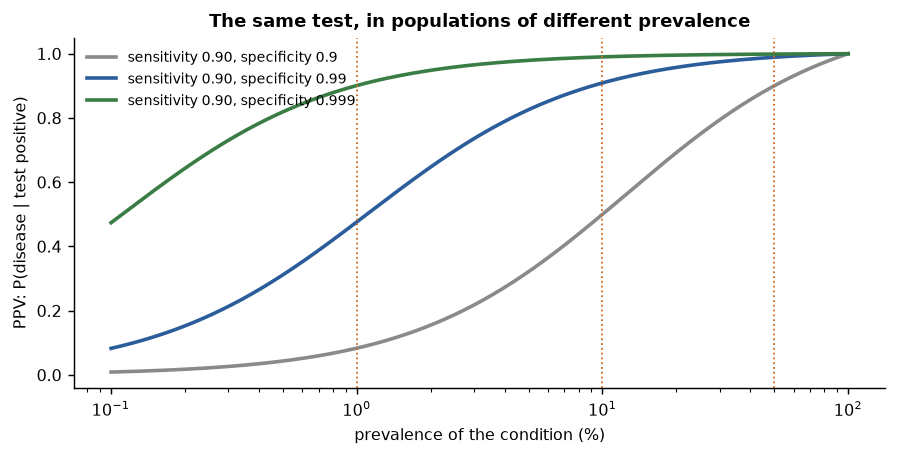

,prevalence 1%,prevalence 10%,prevalence 50%
specificity 0.90,0.083,0.500,0.900
specificity 0.99,0.476,0.909,0.989
specificity 0.999,0.901,0.990,0.999


In [19]:
# PPV en función de la prevalencia para una prueba fija (teorema de Bayes), para tres niveles de especificidad.
def ppv(prev, se, sp):
    return se * prev / (se * prev + (1 - sp) * (1 - prev))
prev = np.logspace(-3, 0, 300)                           # prevalencia de 0.1 % a 100 %
fig, ax = plt.subplots(figsize=(7, 3.6))
for sp, col in [(0.90, GREY), (0.99, BLUE), (0.999, GREEN)]:
    ax.plot(prev * 100, ppv(prev, 0.90, sp), color=col, lw=2, label=f"sensitivity 0.90, specificity {sp}")
for p0 in [0.01, 0.10, 0.50]:
    ax.axvline(p0 * 100, color=ORANGE, ls=":", lw=1)
ax.set_xscale("log"); ax.set_xlabel("prevalence of the condition (%)"); ax.set_ylabel("PPV: P(disease | test positive)")
ax.set_title("The same test, in populations of different prevalence"); ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
tab = pd.DataFrame({f"prevalence {p0:.0%}": [ppv(p0, 0.90, sp) for sp in (0.90, 0.99, 0.999)] for p0 in (0.01, 0.10, 0.50)},
                   index=["specificity 0.90", "specificity 0.99", "specificity 0.999"]).round(3)
tab

<p class="caption"><b>Figura 7.</b> PPV en función de la prevalencia (eje logarítmico) para una sensibilidad de 0.90 y tres especificidades; líneas punteadas en 1 %, 10 % y 50 %. Una prueba con 90 % de especificidad —respetable donde la mitad de los pacientes derivados está enferma— tiene un PPV de aproximadamente 8 % al tamizar una población con 1 % de prevalencia: once de cada doce positivos son falsas alarmas.</p>

La lección se generaliza: un modelo desarrollado donde el 40 % de los pacientes presentaba el desenlace tendrá un PPV mucho menor en atención primaria, donde lo presenta el 4 %, sin ningún cambio en el modelo. La sensibilidad y la especificidad se trasladan entre contextos; los valores predictivos no, y un informe que entrega precisión y sensibilidad sin la prevalencia de su conjunto de prueba ha omitido la información necesaria para usarlo.

### 5.4 De los puntajes a las curvas: ROC

La mayoría de los clasificadores entrega un <strong>puntaje</strong> —una probabilidad, una distancia, un recuento de votos— y la clase se obtiene comparándolo con un <strong>umbral</strong>; 0.5 es una convención, no una ley. En el ejemplo del spam de la clase, los correos con puntaje 0.99 y 0.51 son ambos spam con un umbral de 0.5; subirlo a 0.95 retiene el primero y libera el segundo. Un umbral más alto declara positivos menos casos, de modo que la precisión tiende a subir y la sensibilidad baja; uno más bajo hace lo contrario. La precisión y la sensibilidad se mueven en direcciones opuestas al cambiar el umbral; por eso ninguna se informa sin la otra, y por eso el F1 —su media armónica con igual peso— es un compromiso y no una solución. La tasa de falsos positivos (<em>tasa de falsas alarmas</em>, FP/N) tiene la misma dependencia y solo tiene sentido cuando hay suficientes verdaderos negativos para estimarla; con pocos o ninguno queda indefinida o es inútil, una de las razones por las que se prefiere la curva de precisión–sensibilidad cuando los negativos son escasos o incontables.

La curva <strong>ROC</strong> (receiver operating characteristic, característica operativa del receptor) muestra toda la familia de clasificadores que se obtiene al recorrer el umbral: tasa de verdaderos positivos (sensibilidad) frente a tasa de falsos positivos (1 − especificidad). El área bajo ella, el <strong>AUC</strong>, resume la calidad del ordenamiento; Hanley y McNeil mostraron que es igual a la probabilidad de que un positivo elegido al azar reciba un puntaje más alto que un negativo elegido al azar.<sup class="c"><a href="#r4">[4]</a></sup> Un AUC de 1.0 es un ordenamiento perfecto; 0.5 es aleatorio, no mejor que lanzar una moneda. El tutorial de Fawcett es la referencia estándar sobre su construcción y sus trampas.<sup class="c"><a href="#r5">[5]</a></sup>

**A mano.** Seis pacientes, tres enfermos (D) y tres sanos (H), reciben los puntajes D 0.9, D 0.7, H 0.6, D 0.4, H 0.3, H 0.2. Ordénalos por puntaje y baja el umbral un caso a la vez; cada paso mueve el punto de operación hacia arriba (D) o hacia la derecha (H) en un tercio:

| umbral justo por debajo de | caso | TP | FP | TPR = TP/3 | FPR = FP/3 |
|---|---|---|---|---|---|
| (ninguno positivo) | — | 0 | 0 | 0 | 0 |
| 0.9 | D | 1 | 0 | 1/3 | 0 |
| 0.7 | D | 2 | 0 | 2/3 | 0 |
| 0.6 | H | 2 | 1 | 2/3 | 1/3 |
| 0.4 | D | 3 | 1 | 1 | 1/3 |
| 0.3 | H | 3 | 2 | 1 | 2/3 |
| 0.2 | H | 3 | 3 | 1 | 1 |

El área bajo la escalera es $\tfrac{1}{3}\cdot\tfrac{2}{3} + \tfrac{2}{3}\cdot 1 = \tfrac{8}{9} \approx 0.889$. La interpretación por pares coincide: de los $3 \times 3 = 9$ pares (D, H), los D con puntaje 0.9 y 0.7 superan cada uno a los tres H (6 pares) y el D con puntaje 0.4 supera a dos (2 pares); $8/9$. La celda confirma ambos resultados y los aplica a las probabilidades de validación cruzada de la Sección 5.2.

In [20]:
# Curva ROC y AUC a mano (ordenamiento y conteo acumulado), contrastadas con scikit-learn.
from sklearn.metrics import roc_curve, roc_auc_score
def roc_by_hand(y_true, score):
    '''Return FPR, TPR arrays (one point per case, descending score) and the trapezoidal AUC.'''
    order = np.argsort(-score, kind="stable")                      # el puntaje más alto primero
    yt = np.asarray(y_true)[order]
    tpr = np.r_[0, np.cumsum(yt == 1)] / np.sum(yt == 1)          # positivos acumulados / P
    fpr = np.r_[0, np.cumsum(yt == 0)] / np.sum(yt == 0)          # negativos acumulados / N
    return fpr, tpr, np.trapezoid(tpr, fpr)

def auc_by_pairs(y_true, score):
    '''AUC as the fraction of (positive, negative) pairs in which the positive has the higher score (ties count 1/2).'''
    pos, neg = score[np.asarray(y_true) == 1], score[np.asarray(y_true) == 0]
    diff = pos[:, None] - neg[None, :]
    return ((diff > 0).sum() + 0.5 * (diff == 0).sum()) / diff.size

toy_y = np.array([1, 1, 0, 1, 0, 0]); toy_s = np.array([0.9, 0.7, 0.6, 0.4, 0.3, 0.2])
fpr_t, tpr_t, auc_t = roc_by_hand(toy_y, toy_s)
print("toy example: FPR", np.round(fpr_t, 3), "\n             TPR", np.round(tpr_t, 3))
print(f"toy AUC: trapezoid {auc_t:.4f} | pairwise {auc_by_pairs(toy_y, toy_s):.4f} | sklearn {roc_auc_score(toy_y, toy_s):.4f}  (8/9 = {8/9:.4f})")

fpr_h, tpr_h, auc_h = roc_by_hand(y_pos, prob_cv)
print(f"breast cancer (CV probabilities): AUC by hand {auc_h:.4f} | pairwise {auc_by_pairs(y_pos, prob_cv):.4f} | sklearn {roc_auc_score(y_pos, prob_cv):.4f}")

toy example: FPR [0.    0.    0.    0.333 0.333 0.667 1.   ] 
             TPR [0.    0.333 0.667 0.667 1.    1.    1.   ]
toy AUC: trapezoid 0.8889 | pairwise 0.8889 | sklearn 0.8889  (8/9 = 0.8889)
breast cancer (CV probabilities): AUC by hand 0.9952 | pairwise 0.9952 | sklearn 0.9952


Los tres cálculos coinciden en el ejemplo de juguete (8/9) y en el real, donde el AUC de las probabilidades de la regresión logística con validación cruzada es de aproximadamente 0.99. La celda siguiente dibuja la curva ROC y, a su lado, la curva de <strong>precisión–sensibilidad</strong> (precision–recall, PR) —la precisión frente a la sensibilidad sobre los mismos umbrales— para el problema balanceado de cáncer de mama y para el problema con 1 % de la Sección 5.3, porque la comparación es justamente lo importante.

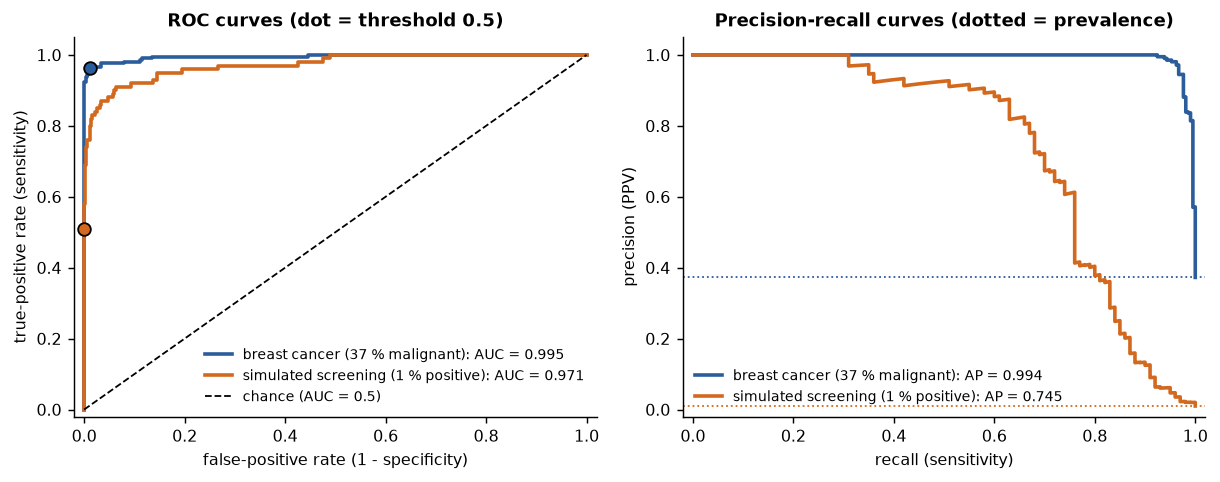

In [21]:
# Curvas ROC y de precisión-sensibilidad para un problema balanceado (cáncer de mama) y uno desbalanceado (1 % de prevalencia).
from sklearn.metrics import precision_recall_curve, average_precision_score
logreg_imb = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xi_tr, yi_tr)
prob_imb = logreg_imb.predict_proba(Xi_te)[:, 1]
cases = {"breast cancer (37 % malignant)": (y_pos, prob_cv, BLUE), "simulated screening (1 % positive)": (yi_te, prob_imb, ORANGE)}

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
for name, (yt, sc, col) in cases.items():
    fpr, tpr, thr = roc_curve(yt, sc)
    axes[0].plot(fpr, tpr, color=col, lw=2, label=f"{name}: AUC = {roc_auc_score(yt, sc):.3f}")
    prec, rec, _ = precision_recall_curve(yt, sc)
    axes[1].plot(rec, prec, color=col, lw=2, label=f"{name}: AP = {average_precision_score(yt, sc):.3f}")
    axes[1].axhline(yt.mean(), color=col, ls=":", lw=1)                         # nivel de azar de la precisión = prevalencia
    i = np.argmin(np.abs(thr - 0.5)); axes[0].plot(fpr[i], tpr[i], "o", color=col, ms=7, mec="k")   # el umbral 0.5
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="chance (AUC = 0.5)")
axes[0].set_xlabel("false-positive rate (1 - specificity)"); axes[0].set_ylabel("true-positive rate (sensitivity)"); axes[0].set_title("ROC curves (dot = threshold 0.5)")
axes[1].set_xlabel("recall (sensitivity)"); axes[1].set_ylabel("precision (PPV)"); axes[1].set_title("Precision-recall curves (dotted = prevalence)")
for ax in axes: ax.legend(frameon=False, fontsize=7.5, loc="lower left" if ax is axes[1] else "lower right"); ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.05)
fig.tight_layout()

<p class="caption"><b>Figura 8.</b> Izquierda: curvas ROC de los dos problemas; ambos AUC son altos (aproximadamente 0.99 y 0.97) y ambas curvas se pegan a la esquina superior izquierda. Derecha: curvas PR de los mismos modelos. En el problema balanceado la curva PR es tan favorecedora como la curva ROC; en el problema con 1 % cae rápidamente, y su línea base (punteada), la precisión de un clasificador aleatorio, es la prevalencia, 0.01. Los puntos marcan el umbral 0.5.</p>

La curva ROC es invariante a la prevalencia porque ambos ejes son tasas dentro de cada clase: esa es su fortaleza para comparar pruebas entre poblaciones y su debilidad en problemas de enfermedades raras, donde una tasa de falsos positivos de 2 % parece despreciable pero, aplicada a 9,900 personas sanas, produce unas 200 falsas alarmas por cada 50 detecciones. La curva PR lo deja en evidencia, y por eso Saito y Rehmsmeier la recomiendan para datos desbalanceados;<sup class="c"><a href="#r6">[6]</a></sup> Davis y Goadrich mostraron que una curva domina en el espacio ROC si y solo si domina en el espacio PR, de modo que ambas nunca discrepan sobre <em>cuál</em> modelo es mejor, solo sobre cuánto mejor parece.<sup class="c"><a href="#r30">[30]</a></sup> El resumen de la curva PR es la <strong>precisión promedio</strong> (average precision, AP) que aparece en la leyenda.

### 5.5 Elegir un umbral según el costo

Una curva ROC es un menú; desplegar un clasificador significa elegir un punto en ella, y el punto correcto depende de cuánto cuestan los errores. Si un falso negativo cuesta $c_{\mathrm{FN}}$ y un falso positivo $c_{\mathrm{FP}}$, un paciente con probabilidad calibrada $p$ debe declararse positivo cuando el costo esperado de declararlo negativo supera al de declararlo positivo, $p\,c_{\mathrm{FN}} > (1-p)\,c_{\mathrm{FP}}$, es decir, cuando

<div class="eq">$$p > t^{*} = \frac{c_{\mathrm{FP}}}{c_{\mathrm{FP}} + c_{\mathrm{FN}}}.$$
<span class="where">Si se considera que un cáncer no detectado cuesta diez veces más que una biopsia innecesaria, $t^{*} = 1/11 \approx 0.09$, muy por debajo de 0.5. El <em>análisis de curvas de decisión</em> (decision curve analysis) de Vickers y Elkin incorpora este razonamiento en un método gráfico estándar.<sup class="c"><a href="#r31">[31]</a></sup> La celda calcula el costo total por cada 100 pacientes para cada umbral y compara el mínimo empírico con $t^{*}$.</span></div>

cost ratio  1:1  cost at t=0.5:    2.3   at empirical optimum t=0.47:    2.1   at t*=0.500:    2.3
cost ratio 10:1  cost at t=0.5:   16.5   at empirical optimum t=0.06:   10.2   at t*=0.091:   13.4
cost ratio 30:1  cost at t=0.5:   48.2   at empirical optimum t=0.06:   13.7   at t*=0.032:   16.9


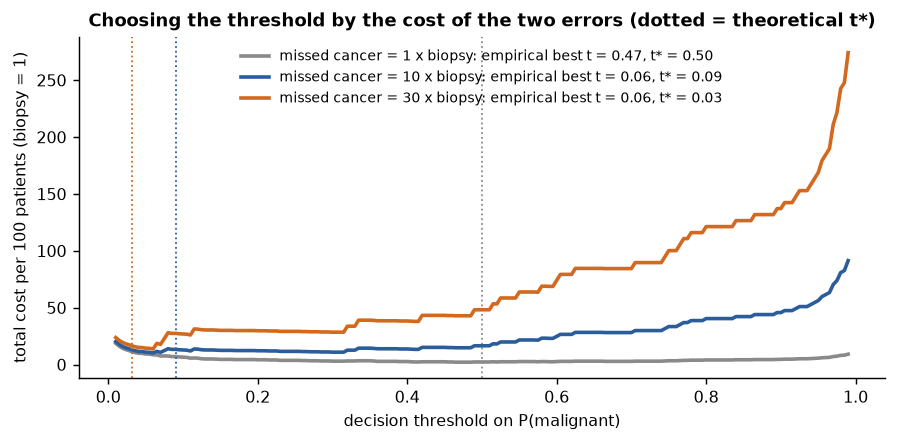

In [22]:
# Costo esperado por cada 100 pacientes en función del umbral de decisión, para dos razones de costo.
thresholds = np.linspace(0.01, 0.99, 197)
def cost_curve(y_true, prob, c_fn, c_fp):
    out = []
    for t in thresholds:
        pred = (prob >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
        out.append((fn * c_fn + fp * c_fp) / len(y_true) * 100)
    return np.array(out)

fig, ax = plt.subplots(figsize=(7, 3.5))
for c_fn, c_fp, col in [(1, 1, GREY), (10, 1, BLUE), (30, 1, ORANGE)]:
    cc = cost_curve(y_pos, prob_cv, c_fn, c_fp)
    t_emp, t_theory = thresholds[np.argmin(cc)], c_fp / (c_fp + c_fn)
    ax.plot(thresholds, cc, color=col, lw=2, label=f"missed cancer = {c_fn} x biopsy: empirical best t = {t_emp:.2f}, t* = {t_theory:.2f}")
    ax.axvline(t_theory, color=col, ls=":", lw=1)
    print(f"cost ratio {c_fn:2d}:1  cost at t=0.5: {cc[np.argmin(np.abs(thresholds-0.5))]:6.1f}   at empirical optimum t={t_emp:.2f}: {cc.min():6.1f}   at t*={t_theory:.3f}: {cc[np.argmin(np.abs(thresholds-t_theory))]:6.1f}")
ax.set_xlabel("decision threshold on P(malignant)"); ax.set_ylabel("total cost per 100 patients (biopsy = 1)")
ax.set_title("Choosing the threshold by the cost of the two errors (dotted = theoretical t*)"); ax.legend(frameon=False, fontsize=7.5)
fig.tight_layout()

<p class="caption"><b>Figura 9.</b> Costo total por cada 100 pacientes en función del umbral para tres razones de costo, a partir de las probabilidades de validación cruzada. Con costos iguales, el mínimo se sitúa cerca de 0.5; a medida que un cáncer no detectado se vuelve más caro, el óptimo se desplaza a la izquierda y el costo de quedarse en 0.5 crece. Los mínimos empíricos son planos y ruidosos —los deciden unos pocos casos limítrofes—, pero caen cerca del $t^{*}$ teórico (punteado), como debe ocurrir cuando las probabilidades están calibradas.</p>

### 5.6 Calibración: una probabilidad debe significar lo que dice

La regla del umbral supone que una probabilidad predicha de 0.3 significa que aproximadamente el 30 % de esos pacientes tiene la enfermedad. Esa propiedad es la <strong>calibración</strong>, y es distinta de la discriminación: un modelo puede ordenar perfectamente a los pacientes (AUC = 1) mientras sus probabilidades están todas comprimidas en [0.45, 0.55] o todas empujadas a 0 y 1. Van Calster y colaboradores llaman a la calibración "el talón de Aquiles de la analítica predictiva", porque rara vez se evalúa y la rompen habitualmente el cambio en la distribución de los datos (dataset shift), la reponderación de clases y el sobreajuste;<sup class="c"><a href="#r10">[10]</a></sup> Steyerberg y Vergouwe la sitúan, junto con la discriminación y la utilidad clínica, entre las tres cosas que un modelo de predicción debe demostrar.<sup class="c"><a href="#r14">[14]</a></sup>

Dos herramientas la evalúan. El <strong>diagrama de confiabilidad</strong> (reliability diagram) agrupa los casos en intervalos según la probabilidad predicha y grafica, para cada intervalo, la fracción observada de positivos frente a la predicción media; un modelo calibrado se ubica sobre la diagonal. El <strong>puntaje de Brier</strong> es la diferencia cuadrática media entre la probabilidad predicha y el desenlace,

<div class="eq">$$\mathrm{BS} = \frac{1}{n} \sum_{i=1}^{n} (p_i - y_i)^2,$$
<span class="where">introducido por Brier en 1950 para los pronósticos meteorológicos;<sup class="c"><a href="#r9">[9]</a></sup> 0 es perfecto, 0.25 corresponde a predecir siempre 0.5, y predecir la prevalencia $\pi$ para todos obtiene $\pi(1-\pi)$. Premia a la vez la discriminación y la calibración. La celda compara tres clasificadores del curso usando probabilidades de validación cruzada.</span></div>

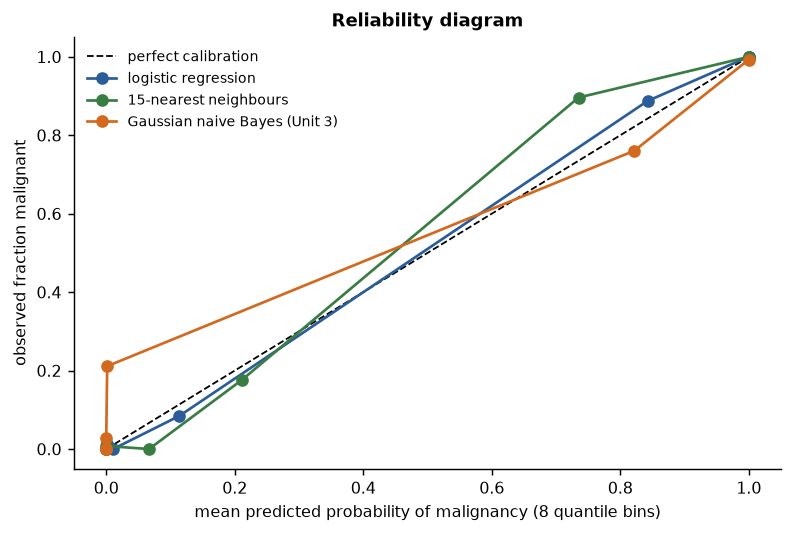

,Brier score,AUC,mean predicted P,"share of P outside (0.02, 0.98)"
model,,,,
logistic regression,0.020,0.995,0.370,0.782
15-nearest neighbours,0.032,0.990,0.356,0.684
Gaussian naive Bayes (Unit 3),0.057,0.987,0.352,0.963


In [23]:
# Diagramas de confiabilidad y puntajes de Brier de tres clasificadores (probabilidades de validación cruzada, positivo = maligno).
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
from sklearn.naive_bayes import GaussianNB
clfs = {"logistic regression": logreg, "15-nearest neighbours": make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
        "Gaussian naive Bayes (Unit 3)": GaussianNB()}
fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
rows = []
for (name, m), col in zip(clfs.items(), [BLUE, GREEN, ORANGE]):
    pr = cross_val_predict(m, X, y_pos, cv=cv10, method="predict_proba")[:, 1]
    frac_pos, mean_pred = calibration_curve(y_pos, pr, n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac_pos, "o-", color=col, label=name)
    rows.append({"model": name, "Brier score": brier_score_loss(y_pos, pr), "AUC": roc_auc_score(y_pos, pr),
                 "mean predicted P": pr.mean(), "share of P outside (0.02, 0.98)": np.mean((pr < 0.02) | (pr > 0.98))})
ax.set_xlabel("mean predicted probability of malignancy (8 quantile bins)"); ax.set_ylabel("observed fraction malignant")
ax.set_title("Reliability diagram"); ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
pd.DataFrame(rows).set_index("model").round(3)

<p class="caption"><b>Figura 10.</b> Diagrama de confiabilidad de tres clasificadores. La regresión logística, ajustada maximizando la verosimilitud de las etiquetas, sigue de cerca la diagonal. Bayes ingenuo tiene un AUC comparable pero probabilidades extremas —la mayoría por debajo de 0.02 o por encima de 0.98— porque su supuesto de independencia multiplica evidencia que en realidad es redundante; está <em>sobreconfiado</em>, y su puntaje de Brier es notablemente peor. Las fracciones de votos de k-NN quedan en un punto intermedio.</p>

La tabla separa las dos cualidades: los AUC están a pocas centésimas unos de otros; los puntajes de Brier, no. Clínicamente, la sobreconfianza no es cosmética: un modelo que dice "2 % de riesgo" cuando el riesgo real entre esos pacientes es 15 % se usará para negar una biopsia justificada. Los modelos cuyas probabilidades no están calibradas por construcción —Bayes ingenuo, SVM, árboles con boosting, la mayoría de las redes neuronales— se <em>recalibran</em> con datos de validación (escalado de Platt, regresión isotónica; <code>CalibratedClassifierCV</code>), y la razón observado/esperado (desenlace medio sobre probabilidad predicha media, 1.0 cuando hay calibración global, calibration-in-the-large) se informa junto al AUC.

<div class="exercise"><h4>Ejercicio 4</h4><p>Envuelve el modelo de Bayes ingenuo en <code>CalibratedClassifierCV(GaussianNB(), method="isotonic", cv=5)</code> y agrégalo al diccionario. Su curva debería desplazarse hacia la diagonal y su puntaje de Brier bajar, mientras su AUC apenas cambia. ¿Por qué la recalibración puede mejorar el puntaje de Brier pero no el AUC? (¿Frente a qué operación es invariante la curva ROC?)</p></div>

## 6. Métricas para regresión

Cuando la variable objetivo es un número —progresión de una enfermedad, glucemia, duración de la estadía hospitalaria—, los errores son los residuos $e_i = y_i - \hat{y}_i$ y los resúmenes estándar son

<div class="eq">$$\mathrm{MSE} = \frac{1}{n}\sum e_i^2, \qquad \mathrm{RMSE} = \sqrt{\mathrm{MSE}}, \qquad \mathrm{MAE} = \frac{1}{n}\sum |e_i|, \qquad R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}.$$
<span class="where">El MSE es lo que minimizan los mínimos cuadrados (Unidad 2) y lo que descompone la Sección 4.3; el RMSE recupera las unidades de la variable objetivo; el MAE, en las mismas unidades, es menos sensible a unos pocos errores grandes y es el que un clínico puede leer directamente ("se equivoca en 45 unidades en promedio"). $R^2$ compara el error cuadrático del modelo con el del predictor más simple, la media de $y$: 1 para un ajuste perfecto, 0 para un modelo que no es mejor que la media.</span></div>

En la muestra de entrenamiento, el $R^2$ de un ajuste por mínimos cuadrados está en $[0, 1]$, porque el ajuste siempre puede hacerlo al menos tan bien como la media. En una muestra de <em>prueba</em> nada lo garantiza: un modelo que predice peor que la media de prueba tiene un <strong>$R^2$ negativo</strong>. Esto no es un error de <code>r2_score</code>; es el informe correcto de que el modelo es peor que inútil en esos datos. Las celdas muestran el caso sano y el patológico con los datos de diabetes.<sup class="c"><a href="#r21">[21]</a></sup>

In [24]:
# Métricas de regresión a mano y con scikit-learn: regresión lineal en los datos de progresión de diabetes.
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
diab = datasets.load_diabetes()
Xd, yd = diab.data, diab.target                        # 442 pacientes, 10 variables basales estandarizadas; objetivo = progresión al cabo de un año
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.3, random_state=0)
lin = LinearRegression().fit(Xd_tr, yd_tr)
e = yd_te - lin.predict(Xd_te)                          # residuos de prueba
by_hand = {"MSE": np.mean(e ** 2), "RMSE": np.sqrt(np.mean(e ** 2)), "MAE": np.mean(np.abs(e)),
           "R2": 1 - np.sum(e ** 2) / np.sum((yd_te - yd_te.mean()) ** 2)}
skl = {"MSE": mean_squared_error(yd_te, lin.predict(Xd_te)), "RMSE": np.sqrt(mean_squared_error(yd_te, lin.predict(Xd_te))),
       "MAE": mean_absolute_error(yd_te, lin.predict(Xd_te)), "R2": r2_score(yd_te, lin.predict(Xd_te))}
print(f"target: mean {yd_te.mean():.1f}, SD {yd_te.std():.1f} on the {len(yd_te)} test patients | training R2 = {lin.score(Xd_tr, yd_tr):.3f}")
pd.DataFrame({"by hand": by_hand, "scikit-learn": skl}).round(3)

target: mean 152.2, SD 71.4 on the 133 test patients | training R2 = 0.554


,by hand,scikit-learn
MSE,3097.119,3097.119
RMSE,55.652,55.652
MAE,44.618,44.618
R2,0.393,0.393


El RMSE (aproximadamente 56) supera al MAE (aproximadamente 45), como ocurre siempre que unos pocos residuos son grandes; ambos deben leerse frente a la dispersión de la variable objetivo (SD de aproximadamente 71): el modelo elimina parte de la variación, no la mayor parte, que es lo que dice en términos relativos el $R^2$ de prueba de aproximadamente 0.39. El $R^2$ de entrenamiento es mayor, como predice la Sección 1.2. Ahora, el caso patológico.

In [25]:
# R2 negativo en el conjunto de prueba: regresión polinomial de grado creciente sobre la misma división.
from sklearn.preprocessing import PolynomialFeatures
rows = []
for deg in [1, 2, 3]:
    poly = make_pipeline(PolynomialFeatures(deg), LinearRegression()).fit(Xd_tr, yd_tr)
    rows.append({"degree": deg, "number of coefficients": poly[-1].coef_.size, "train R2": poly.score(Xd_tr, yd_tr),
                 "test R2": poly.score(Xd_te, yd_te), "test RMSE": np.sqrt(mean_squared_error(yd_te, poly.predict(Xd_te)))})
rmse_mean = np.sqrt(np.mean((yd_te - yd_tr.mean()) ** 2))
print(f"RMSE of predicting the training mean for every test patient: {rmse_mean:.1f}  (R2 = {r2_score(yd_te, np.full_like(yd_te, yd_tr.mean())):.4f})")
pd.DataFrame(rows).set_index("degree").round(3)

RMSE of predicting the training mean for every test patient: 71.4  (R2 = -0.0000)


,number of coefficients,train R2,test R2,test RMSE
degree,,,,
1,11,0.554,0.393,55.652
2,66,0.657,0.225,62.864
3,286,0.931,-22.873,348.979


Con 10 variables, un polinomio de grado 3 tiene cientos de coeficientes ajustados a unos 300 pacientes. Su $R^2$ de entrenamiento sube por encima de 0.9 y su $R^2$ de prueba es un número negativo grande: sus predicciones son mucho peores que decirle a cada paciente la progresión promedio. Es la Sección 4 vestida de regresión. Observa también que el predictor trivial de la media obtiene un $R^2$ prácticamente nulo en el conjunto de prueba (difiere de cero exacto solo porque la media de entrenamiento no es la media de prueba).

<div class="box key"><h4>Cómo informar un modelo de regresión</h4><p>Informa el RMSE o el MAE en las unidades de la variable objetivo, con la SD de la variable objetivo al lado, y el $R^2$ de prueba. Nunca $R^2$ solo: 0.9 para una cantidad que varía mil veces puede ocultar errores clínicamente inútiles, y 0.3 puede ser excelente para un desenlace ruidoso.</p></div>

## 7. Fuga de datos

La <strong>fuga de datos</strong> (leakage) es el uso, durante el entrenamiento, de información que no estará disponible cuando el modelo se despliegue —información que se filtra desde el conjunto de prueba, o desde el futuro, hacia el modelo. Produce evaluaciones honestas en la forma (se reservó un conjunto de prueba, se ejecutó una validación cruzada) y erróneas en el fondo. Kaufman y colaboradores dieron la primera descripción sistemática;<sup class="c"><a href="#r11">[11]</a></sup> Kapoor y Narayanan revisaron 294 artículos de 17 campos cuyos resultados se descubrió después que estaban inflados por fuga de datos, y propusieron una taxonomía y una lista de verificación.<sup class="c"><a href="#r12">[12]</a></sup> Esta sección demuestra las tres formas que explican la mayoría de los casos, cada una con el número inflado junto al honesto.

### 7.1 Preprocesar antes de dividir

Todo paso que <em>aprende de los datos</em> —selección de características, estandarización, imputación, reducción de dimensionalidad— debe ajustarse solo en la partición de entrenamiento. Seleccionar características en el conjunto de datos completo y luego aplicar validación cruzada al clasificador es la versión más dañina, porque la selección ya vio las etiquetas de prueba; Ambroise y McLachlan mostraron en 2002 que los clasificadores de expresión génica evaluados de esta forma informaban un error cercano a cero en datos sin señal.<sup class="c"><a href="#r24">[24]</a></sup> El remedio es poner el preprocesamiento <em>dentro</em> del <code>Pipeline</code>, para que <code>cross_val_score</code> lo reajuste en cada partición de entrenamiento. La celda muestra la fuga en ruido puro (1,000 características, 200 casos, etiquetas aleatorias) y, como contraste, la fuga por escalamiento en los datos de cáncer de mama.

In [26]:
# Fuga 1: selección de características (y, como contraste, escalamiento) realizada antes de dividir frente a dentro del pipeline.
from sklearn.feature_selection import SelectKBest, f_classif
cv5 = StratifiedKFold(5, shuffle=True, random_state=0)
rng = np.random.default_rng(0)
leaky, honest = [], []
for rep in range(5):                                            # 5 conjuntos de datos de ruido independientes
    Xn, yn = rng.normal(size=(200, 1000)), rng.integers(0, 2, 200)
    X_sel = SelectKBest(f_classif, k=20).fit_transform(Xn, yn)   # INCORRECTO: la selección ha visto todas las etiquetas, incluidas las de las particiones de prueba
    leaky.append(cross_val_score(KNeighborsClassifier(5), X_sel, yn, cv=cv5).mean())
    honest.append(cross_val_score(make_pipeline(SelectKBest(f_classif, k=20), KNeighborsClassifier(5)), Xn, yn, cv=cv5).mean())
print(f"feature selection on NOISE (true accuracy 0.5): selected before CV {np.mean(leaky):.3f} | selected inside the pipeline {np.mean(honest):.3f}")

X_scaled_all = StandardScaler().fit_transform(X)                # INCORRECTO en principio: el escalador ha visto las particiones de prueba
leaky_sc = cross_val_score(KNeighborsClassifier(5), X_scaled_all, y, cv=cv5).mean()
honest_sc = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(5)), X, y, cv=cv5).mean()
print(f"scaling on the breast-cancer data: scaled before CV {leaky_sc:.4f} | scaled inside the pipeline {honest_sc:.4f}")

feature selection on NOISE (true accuracy 0.5): selected before CV 0.663 | selected inside the pipeline 0.490
scaling on the breast-cancer data: scaled before CV 0.9649 | scaled inside the pipeline 0.9649


En datos sin señal, seleccionar las 20 "mejores" de 1,000 características de ruido antes de la validación cruzada da una exactitud muy por encima del azar —un resultado que pasaría una revisión por pares—, mientras que la misma selección dentro del pipeline da el valor honesto, cercano a 0.5. La fuga por escalamiento no cambia de forma visible la exactitud en cáncer de mama con cuatro decimales: el escalador aprende dos números por característica, que la partición de prueba apenas mueve. El daño es proporcional a cuánto aprende el preprocesamiento de las etiquetas; el hábito del <code>Pipeline</code> no cuesta nada y cubre ambos casos.

### 7.2 Características derivadas de la variable objetivo

La segunda fuga es una característica que es consecuencia del desenlace y no un predictor de él: el tratamiento prescrito después del diagnóstico, un examen solicitado porque el clínico ya sospechaba la enfermedad, un código de facturación generado por el propio evento que se predice. Estas características son extremadamente predictivas en la base de datos retrospectiva y no están disponibles en el momento de la predicción. La simulación añade un "código de tratamiento posbiopsia" que coincide con el resultado de la biopsia en el 95 % de los casos.

In [27]:
# Fuga 2: una característica derivada del desenlace (disponible en la base de datos, no en el momento de la predicción).
rng = np.random.default_rng(1)
treatment_code = np.where(rng.random(len(y)) < 0.95, y_pos, 1 - y_pos)      # 'tratamiento administrado' coincide con la biopsia el 95 % de las veces
X_leaky = np.c_[X, treatment_code]
honest_acc = cross_val_score(logreg, X, y_pos, cv=cv10).mean()
leaky_acc = cross_val_score(logreg, X_leaky, y_pos, cv=cv10).mean()
coef = logreg.fit(StandardScaler().fit_transform(X_leaky), y_pos)[-1].coef_[0] if False else make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_leaky, y_pos)[-1].coef_[0]
rank = int(np.argsort(-np.abs(coef)).tolist().index(30)) + 1
print(f"CV accuracy without the leaked feature: {honest_acc:.3f}   with it: {leaky_acc:.3f}")
print(f"the leaked feature has the {rank}{'st' if rank == 1 else 'th'} largest standardised coefficient of 31 (|coef| = {abs(coef[30]):.2f}, next largest {np.sort(np.abs(coef))[-2]:.2f})")

CV accuracy without the leaked feature: 0.977   with it: 0.988
the leaked feature has the 1st largest standardised coefficient of 31 (|coef| = 2.21, next largest 0.98)


La exactitud sube y el modelo se apoya en la columna filtrada más que en cualquier medición nuclear. La validación cruzada no puede detectarlo, porque la fuga está presente en todas las particiones. La defensa es clínica, no estadística —para cada característica, pregúntate <em>¿se conoce este valor en el momento en que se necesita la predicción?</em>—, y el ítem de TRIPOD+AI sobre el momento de medición de cada predictor existe por esta razón (Sección 8).

### 7.3 Mediciones repetidas por paciente

La tercera fuga es estructural. Cuando los pacientes aportan varios registros —visitas, imágenes, segmentos de ECG—, la división aleatoria pone algunos registros de un paciente en entrenamiento y otros en prueba. El modelo entonces reconoce al <em>paciente</em>, no la condición. Saeb y colaboradores mostraron que la validación cruzada por registro de datos de sensores clínicos infla drásticamente la exactitud respecto de la validación cruzada por sujeto, y que la mayoría de los estudios publicados había usado la equivocada.<sup class="c"><a href="#r25">[25]</a></sup> El remedio es <code>GroupKFold</code> (Figura 3). La simulación construye 100 pacientes con 8 registros cada uno; cada paciente tiene una línea basal individual en todas las características (lo que hace reconocibles sus registros) y la enfermedad desplaza moderadamente tres características.

In [28]:
# Fuga 3: varios registros por paciente, división aleatoria (por registro) frente a por paciente (GroupKFold).
rng = np.random.default_rng(0)
n_pat, n_rec = 100, 8
label_pat = rng.integers(0, 2, n_pat)                                   # un diagnóstico por paciente
baseline_pat = rng.normal(0, 1.5, (n_pat, 10))                          # línea basal propia de cada paciente en 10 características
effect = 1.5 * np.r_[np.ones(3), np.zeros(7)]                           # la enfermedad desplaza 3 de las 10 características
X_rep = np.vstack([baseline_pat[p] + effect * label_pat[p] + rng.normal(0, 1, 10) for p in range(n_pat) for _ in range(n_rec)])
y_rep, patient = np.repeat(label_pat, n_rec), np.repeat(np.arange(n_pat), n_rec)

knn = make_pipeline(StandardScaler(), KNeighborsClassifier(5))
record_wise = cross_val_score(knn, X_rep, y_rep, cv=KFold(5, shuffle=True, random_state=0)).mean()
patient_wise = cross_val_score(knn, X_rep, y_rep, cv=GroupKFold(5, shuffle=True, random_state=0), groups=patient).mean()
print(f"{len(y_rep)} records from {n_pat} patients")
print(f"record-wise 5-fold CV (patients leak across folds): {record_wise:.3f}")
print(f"patient-wise 5-fold CV (GroupKFold):                 {patient_wise:.3f}")

800 records from 100 patients
record-wise 5-fold CV (patients leak across folds): 0.859
patient-wise 5-fold CV (GroupKFold):                 0.670


La validación cruzada por registro informa una exactitud muy superior a la de la validación por paciente. La primera responde "¿puede el modelo clasificar un registro nuevo de un paciente que ya ha visto?" —casi nunca la pregunta clínica. La segunda responde "¿puede clasificar a un paciente nuevo?", y es mucho menor porque el efecto de la enfermedad es moderado en relación con la variación entre pacientes. La misma lógica se aplica a cualquier agrupación que no se repetirá en el despliegue: dividir por hospital para estimar el desempeño en un hospital nuevo, por año para estimar el desempeño del año siguiente.

<div class="box warn"><h4>La fuga de datos es silenciosa</h4><p>Ninguna de las tres fugas produce una advertencia ni un número inverosímil: las exactitudes con fuga de arriba son valores que un revisor aceptaría. Se descubren razonando sobre el proceso que generó los datos, no inspeccionando la salida. La lista de verificación de Kapoor y Narayanan —¿separación limpia entre entrenamiento y prueba en cada paso de preprocesamiento? ¿alguna característica no disponible en el momento de la predicción? ¿duplicados o grupos a ambos lados de la división? ¿la distribución de prueba coincide con la del despliegue?— debería aplicarse a cada evaluación antes de creer su número.<sup class="c"><a href="#r12">[12]</a></sup></p></div>

## 8. Validación interna frente a externa, e informe de resultados

Todo lo anterior es <strong>validación interna</strong>: los casos de prueba, por cuidadosamente que se hayan reservado, provienen de la misma fuente que los casos de entrenamiento —el mismo hospital, escáneres, años, criterios de inclusión, etiquetado. Estima el desempeño <em>en esa fuente</em>. El desempeño en otro lugar es una cantidad distinta, que solo se estima mediante <strong>validación externa</strong>: aplicar el modelo congelado, sin reajustarlo, a datos recolectados en otro lugar, más tarde o con otros criterios.<sup class="c"><a href="#r14">[14]</a>,<a href="#r28">[28]</a></sup> Revela lo que la validación interna no puede: atajos (Unidad 1, Sección 7.3, donde un identificador del escáner predecía la etiqueta en un hospital y no en otros), descalibración por una prevalencia o una mezcla de casos distinta, y deterioro por diferencias entre poblaciones. El modelo de sepsis de la Unidad 1 es el caso canónico: números internos excelentes, una sensibilidad de 33 % en la validación externa.<sup class="c"><a href="#r32">[32]</a></sup>

La celda simula esta estructura con los datos de cáncer de mama, usando una característica como sustituto del "centro": el modelo se desarrolla con los tumores cuya <em>simetría media</em> ("mean symmetry") está bajo la mediana (un "hospital") y se aplica, congelado, a los que están sobre la mediana (otro "hospital", con una mezcla de casos distinta y más tumores malignos).

In [29]:
# Validación interna (validación cruzada, mismo 'hospital') frente a externa (modelo congelado, otro 'hospital').
site = (cancer.data["mean symmetry"] > cancer.data["mean symmetry"].median()).to_numpy()   # False = centro de desarrollo, True = centro externo
X_dev, y_dev, X_ext, y_ext = X[~site], y_pos[~site], X[site], y_pos[site]
internal_prob = cross_val_predict(logreg, X_dev, y_dev, cv=cv10, method="predict_proba")[:, 1]
external_prob = logreg.fit(X_dev, y_dev).predict_proba(X_ext)[:, 1]                       # modelo congelado, nunca reajustado
def report(yt, pr):
    tn, fp, fn, tp = confusion_matrix(yt, (pr >= 0.5).astype(int)).ravel()
    return {"prevalence": yt.mean(), "accuracy": (tp + tn) / len(yt), "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp),
            "AUC": roc_auc_score(yt, pr), "Brier": brier_score_loss(yt, pr), "observed / expected": yt.mean() / pr.mean()}
print(f"development site: {len(y_dev)} tumours | external site: {len(y_ext)} tumours")
pd.DataFrame({"internal (CV, development site)": report(y_dev, internal_prob), "external (frozen model, other site)": report(y_ext, external_prob)}).T.round(3)

development site: 285 tumours | external site: 284 tumours


,prevalence,accuracy,sensitivity,specificity,AUC,Brier,observed / expected
"internal (CV, development site)",0.232,0.972,0.879,1.000,0.976,0.029,1.032
"external (frozen model, other site)",0.514,0.919,1.000,0.833,0.998,0.050,0.861


El patrón es el que advierte Van Calster.<sup class="c"><a href="#r10">[10]</a></sup> La discriminación sobrevive: el AUC externo es tan alto como el interno, de modo que el modelo sigue ordenando los malignos por encima de los benignos. La calibración y las métricas que dependen del umbral, no. En el centro externo la malignidad es aproximadamente el doble de prevalente y los tumores se ven más sospechosos en todas las características, y el modelo —entrenado donde esos tumores eran casi siempre malignos— ahora sobrediagnostica malignidad: su riesgo predicho medio supera la prevalencia observada (observado/esperado menor que 1), la sensibilidad sube a 1.0 pero la especificidad cae de 1.00 a aproximadamente 0.83 (uno de cada seis tumores benignos enviado a biopsia), la exactitud baja unos cinco puntos y el puntaje de Brier empeora. Un informe que entregara solo el AUC calificaría a este modelo de transportable; uno que entregara la especificidad en el umbral desplegado y la calibración exigiría recalibrar antes del despliegue —la conclusión correcta. La dirección de la descalibración (sobrepredicción o subpredicción) depende del cambio; lo general es que un umbral congelado no sobrevive a un cambio en la mezcla de casos.

### 8.1 Qué informar: TRIPOD+AI

La declaración <strong>TRIPOD+AI</strong> (Transparent Reporting of a multivariable prediction model for Individual Prognosis Or Diagnosis, actualización de 2024 para aprendizaje automático) es el estándar de informe que las revistas médicas exigen para los modelos de predicción.<sup class="c"><a href="#r13">[13]</a></sup> En el vocabulario de este suplemento, sus ítems relativos a la evaluación son:

- **Fuente de los datos y contexto** del desarrollo y de cada validación; fechas; criterios de elegibilidad —para que el lector pueda juzgar <em>de qué</em> es muestra la muestra de prueba.
- Definición y momento del **desenlace**; **predictores**, con el momento en que se mide cada uno respecto del desenlace (la defensa frente a la Sección 7.2).
- **Tamaño muestral** y su justificación; Riley y colaboradores dan el cálculo,<sup class="c"><a href="#r27">[27]</a></sup> y la fórmula binomial de la Sección 2.1 es la versión rápida, de servilleta.
- **Desarrollo del modelo**: todos los modelos candidatos e hiperparámetros probados, y cómo se seleccionaron (Sección 3.4). **Datos faltantes** tratados dentro del pipeline.
- **Método de validación**: interna (qué remuestreo, cuántas particiones, anidada o no, agrupada según qué) y externa (qué población).
- **Medidas de desempeño**: discriminación (AUC con un intervalo de confianza), calibración (gráfico y resumen), medidas dependientes del umbral en un umbral <em>preespecificado</em> junto con la prevalencia de la muestra (Secciones 5.3–5.6); en regresión, el error en las unidades de la variable objetivo (Sección 6). El marco de Steyerberg las organiza.<sup class="c"><a href="#r26">[26]</a></sup>
- **Equidad**: desempeño en subgrupos relevantes (sexo, edad, etnia, centro), el añadido de TRIPOD+AI que conecta con la Unidad 1, Sección 7. **Disponibilidad** del código, los datos y el modelo.

Relee el ejemplo del atajo de la Unidad 1 con esta lista. El modelo con la característica del escáner informó una exactitud de entrenamiento (Sección 1.2: no es una medición), una exactitud en casos nuevos del mismo hospital (validación interna: desempeño solo en ese hospital) y una exactitud en un hospital nuevo (validación externa), y solo la tercera reveló la falla. Un informe conforme a TRIPOD+AI también habría enumerado el "identificador del escáner" entre los predictores, con su momento de medición, y un lector se habría preguntado por qué un escáner debería predecir un diagnóstico.

<div class="box bridge"><h4>Puente hacia los talleres del curso</h4><p>El Taller 2 te pide presentar un artículo que aplique aprendizaje supervisado. Usa la lista anterior como pauta de lectura: para cada ítem, anota qué informa el artículo y qué omite. Un artículo que informa la exactitud sin el tamaño de prueba, una métrica dependiente del umbral sin la prevalencia, o un AUC sin calibración no ha aportado la evidencia que necesita un clínico; decirlo con precisión es la habilidad que evalúa el taller.</p></div>

## 9. Una función de evaluación reutilizable

Las unidades posteriores necesitan, una y otra vez, la misma evaluación: validación cruzada estratificada repetida de varios clasificadores con las métricas de la Sección 5, el AUC y el puntaje de Brier, y una medida de incertidumbre. La función siguiente la empaqueta; cópiala en cualquier notebook. Recibe un diccionario de modelos, datos con la clase positiva codificada como 1 y un divisor (por defecto, 5 particiones estratificadas repetidas 5 veces; pasa <code>GroupKFold</code> con <code>groups=</code> cuando los pacientes se repiten), y devuelve la media y la SD entre particiones para cada métrica. Todos los modelos se comparan en las <em>mismas</em> particiones, lo que elimina de la comparación el ruido entre divisiones de la Figura 2.

In [30]:
# Una función de evaluación reutilizable para clasificadores binarios (copia esta celda en notebooks posteriores).
from sklearn.base import clone
def evaluate_classifiers(models, X, y, cv=None, groups=None, threshold=0.5):
    '''Repeated cross-validation of several binary classifiers on the SAME folds.
    models: dict name -> estimator with predict_proba; y: 0/1 with 1 = the condition to detect.
    Returns a DataFrame with mean and SD across folds of each metric.'''
    if cv is None:
        cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)
    X, y = np.asarray(X), np.asarray(y)
    records = []
    for name, model in models.items():
        for fold, (tr, te) in enumerate(cv.split(X, y, groups=groups)):
            prob = clone(model).fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
            tn, fp, fn, tp = confusion_matrix(y[te], (prob >= threshold).astype(int), labels=[0, 1]).ravel()
            records.append({"model": name, "fold": fold, "accuracy": (tp + tn) / len(te),
                            "sensitivity": tp / max(tp + fn, 1), "specificity": tn / max(tn + fp, 1),
                            "PPV": tp / max(tp + fp, 1), "NPV": tn / max(tn + fn, 1),
                            "balanced acc.": 0.5 * (tp / max(tp + fn, 1) + tn / max(tn + fp, 1)),
                            "MCC": matthews_corrcoef(y[te], (prob >= threshold).astype(int)),
                            "AUC": roc_auc_score(y[te], prob), "Brier": brier_score_loss(y[te], prob)})
    long = pd.DataFrame(records).drop(columns="fold")
    summary = long.groupby("model", observed=True, sort=False).agg(["mean", "std"])
    return summary.round(3)

# Cómo usarla: tres clasificadores del curso en los datos de cáncer de mama, clase positiva = maligno.
models = {"logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
          "5-nearest neighbours": make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
          "Gaussian naive Bayes": GaussianNB()}
results = evaluate_classifiers(models, X, y_pos)
results[["accuracy", "sensitivity", "specificity", "AUC", "Brier"]]      # las columnas restantes están en `results`

accuracy        sensitivity        specificity           AUC         Brier       
                         mean    std        mean    std        mean    std   mean    std   mean    std
model                                                                                                 
logistic regression     0.977  0.016       0.957  0.030       0.989  0.017  0.995  0.005  0.019  0.008
5-nearest neighbours    0.967  0.019       0.928  0.046       0.990  0.011  0.985  0.013  0.029  0.013
Gaussian naive Bayes    0.938  0.021       0.887  0.061       0.968  0.016  0.988  0.007  0.057  0.020

La tabla se lee como un resumen al estilo TRIPOD: discriminación (AUC), calibración (Brier) y las dos tasas clínicas en el umbral preespecificado, cada una con su SD entre particiones, sobre particiones idénticas. Las diferencias menores que aproximadamente una SD no deben interpretarse; la diferencia de Brier entre Bayes ingenuo y los demás es de varias SD y es real. Las columnas restantes —PPV, NPV, exactitud balanceada, MCC— están en <code>results</code>. Las Unidades 3, 4 y 6 llaman a esta función con sus propios diccionarios de modelos.

<div class="exercise"><h4>Ejercicio 5</h4><p>Llama a la función con <code>cv=GroupKFold(5)</code> y <code>groups=patient</code> sobre los datos de mediciones repetidas de la Sección 7.3, y con <code>threshold=0.09</code> sobre los datos de cáncer de mama (el umbral derivado de los costos de la Sección 5.5). Explica cada columna que cambia entre el umbral 0.5 y el 0.09, y la única columna que no cambia.</p></div>

## 10. Resumen

Ahora deberías poder explicar, sin apuntes:

- Por qué el error de entrenamiento está sesgado de forma optimista, y los roles de las muestras de entrenamiento, validación y prueba (y que la muestra de prueba se usa una sola vez).
- Por qué una única exactitud en reserva (hold-out) es un sorteo de una distribución cuyo ancho está determinado por el tamaño de prueba, y de qué protege la estratificación.
- Cómo funciona, a mano, la validación cruzada de k particiones; cuándo son apropiadas las variantes estratificada, repetida, dejar uno fuera y agrupada; y por qué seleccionar hiperparámetros e informar el desempeño en las mismas particiones es optimista (CV anidada).
- El sobreajuste y el subajuste en términos de la complejidad del modelo; la descomposición sesgo–varianza, su total en forma de U, y cómo lo muestran la curva de complejidad y la curva de aprendizaje; la maldición de la dimensionalidad y la razón $p/n$.
- La matriz de confusión y cada métrica derivada de ella, con sus nombres de aprendizaje automático y clínicos; por qué la exactitud falla ante el desbalance; por qué el PPV depende de la prevalencia (Bayes) mientras que la sensibilidad y la especificidad no.
- Cómo se construye una curva ROC a partir de puntajes, qué significa el AUC como probabilidad, cuándo es más informativa la curva de precisión–sensibilidad, cómo se deduce un umbral de los costos de los dos errores, y qué es la calibración y cómo evaluarla.
- MSE, RMSE, MAE y $R^2$, y por qué $R^2$ es negativo cuando un modelo es peor que la media.
- Las tres fugas clásicas —preprocesar antes de dividir, características derivadas de la variable objetivo, pacientes repetidos entre particiones—, cómo cada una infla un número y cómo se previene cada una.
- La diferencia entre validación interna y externa, qué estima cada una, y los ítems de TRIPOD+AI que debe contener el informe de un modelo.

## 11. Autoevaluación

<details><summary>1. Un colega informa "nuestra red neuronal alcanza 98 % de exactitud en el conjunto de entrenamiento". Enumera las tres preguntas que harías antes de tomar en serio el número, y di qué enseña un clasificador 1-NN sobre la primera de ellas.</summary>¿En qué casos se midió (entrenamiento, validación o prueba)? ¿Cómo se separaron de los datos de entrenamiento (división aleatoria, por paciente, por hospital, por fecha)? ¿Cuántos eran? En el conjunto de entrenamiento, 1-NN alcanza 100 % por construcción, sean cuales sean los datos, de modo que la exactitud de entrenamiento no es una medición de nada.</details>

<details><summary>2. Un conjunto de prueba tiene 50 casos y la exactitud medida es 0.90. Da el error estándar aproximado y di si se ha demostrado que un segundo modelo con 0.94 en el mismo conjunto de prueba es mejor.</summary>$\sqrt{0.9 \times 0.1 / 50} \approx 0.042$. Una diferencia de 0.04 equivale a aproximadamente un error estándar; no se ha demostrado. Se necesita una comparación pareada en las mismas particiones, o un conjunto de prueba mucho más grande.</details>

<details><summary>3. Escribe los índices de prueba de las cuatro particiones de <code>KFold(4)</code> sin barajar sobre 10 casos (índices 0–9), sabiendo que <code>np.array_split</code> hace más grandes las primeras particiones.</summary>{0, 1, 2}, {3, 4, 5}, {6, 7}, {8, 9}. El conjunto de entrenamiento de cada partición es el complemento. Si los casos estuvieran ordenados por clase, la primera partición se entrenaría con una muestra empobrecida en su propia clase, y por eso se usa <code>shuffle=True</code>.</details>

<details><summary>4. Explica en una oración cada cosa: por qué dejar uno fuera tiene bajo sesgo y alta varianza, y cuándo se prefiere k-fold estratificado sobre k-fold simple.</summary>Bajo sesgo porque cada modelo se entrena con $n-1$ casos, casi la muestra completa; alta varianza porque los $n$ conjuntos de entrenamiento se superponen casi por completo, de modo que los $n$ errores están muy correlacionados y su promedio fluctúa con la muestra particular. Se prefiere k-fold estratificado cuando el conjunto de datos es pequeño o desbalanceado, para que cada partición contenga la misma proporción de cada clase.</details>

<details><summary>5. En el experimento de CV anidada sobre ruido, el mejor puntaje interno estuvo por encima de 0.5 y la estimación anidada fue de aproximadamente 0.5. ¿Qué número aparecería en un artículo que ajustó en el conjunto de prueba, y qué principio general ilustra la diferencia?</summary>El mejor puntaje interno: el máximo de muchas estimaciones ruidosas, sesgado hacia arriba. El principio: los datos usados para tomar una decisión (modelo, hiperparámetro, característica, umbral) no pueden usarse también para informar el desempeño de lo elegido; por cada nivel de mirar se requiere un nivel más de reserva.</details>

<details><summary>6. Con la formulación de la diapositiva, define sesgo y varianza, di cuál conduce al subajuste y cuál al sobreajuste, y nombra la perilla que mueve a k-NN entre ambos.</summary>El sesgo es el error que proviene de supuestos erróneos del modelo (una forma demasiado simple) y conduce al subajuste; la varianza es la sensibilidad a pequeñas fluctuaciones del conjunto de entrenamiento y conduce al sobreajuste. La perilla es $k$: un $k$ pequeño da bajo sesgo y alta varianza; un $k$ grande, lo contrario.</details>

<details><summary>7. Calcula a mano, para TP = 40, FN = 10, FP = 20, TN = 930: exactitud, sensibilidad, especificidad, PPV, NPV, F1 y exactitud balanceada.</summary>Exactitud 970/1000 = 0.970; sensibilidad 40/50 = 0.80; especificidad 930/950 ≈ 0.979; PPV 40/60 ≈ 0.667; NPV 930/940 ≈ 0.989; F1 = 80/(80 + 20 + 10) ≈ 0.727; exactitud balanceada ≈ 0.889. La exactitud está dominada por los 950 negativos.</details>

<details><summary>8. Una prueba tiene sensibilidad 0.95 y especificidad 0.95. Calcula su PPV con 50 % de prevalencia y con 1 % de prevalencia, y explica en una oración por qué difieren.</summary>Con 50 %: $0.95 \times 0.5 / (0.95 \times 0.5 + 0.05 \times 0.5) = 0.95$. Con 1 %: $0.0095 / (0.0095 + 0.0495) \approx 0.161$. Con baja prevalencia, las falsas alarmas, que provienen del gran grupo de sanos, superan en número a los verdaderos positivos, que provienen del pequeño grupo de enfermos.</details>

<details><summary>9. Los puntajes de 4 pacientes enfermos son 0.8, 0.6, 0.5, 0.2 y los de 3 pacientes sanos 0.7, 0.4, 0.1. Calcula el AUC contando pares.</summary>12 pares. 0.8 supera a 3; 0.6 supera a 2 (0.4, 0.1); 0.5 supera a 2; 0.2 supera a 1 (0.1). AUC = 8/12 ≈ 0.667.</details>

<details><summary>10. Dos modelos tienen el mismo AUC de 0.90. Uno tiene un puntaje de Brier de 0.08 y el otro de 0.20. ¿Qué concluyes, y cuál de los dos puede usarse con la regla del umbral basada en costos $t^{*} = c_{FP}/(c_{FP} + c_{FN})$?</summary>Ordenan a los pacientes igual de bien, pero el segundo está mal calibrado: sus probabilidades no coinciden con las frecuencias observadas. La regla del umbral supone probabilidades calibradas, de modo que solo el primero puede usarla directamente; el segundo debe recalibrarse primero (escalado de Platt, regresión isotónica).</details>

<details><summary>11. Lee este código y di qué tiene de incorrecto y qué número inflará:<br><code>X_sel = SelectKBest(k=10).fit_transform(X, y)</code><br><code>scores = cross_val_score(SVC(), X_sel, y, cv=5)</code></summary>La selección de características se ajustó con todos los datos, incluidos los casos que cada partición usa después para la prueba, de modo que las características seleccionadas ya "vieron" las etiquetas de prueba. La exactitud de CV queda inflada: en ruido puro sube muy por encima de 0.5. El selector debe ir dentro de un <code>Pipeline</code> que se pase a <code>cross_val_score</code>.</details>

<details><summary>12. Un modelo desarrollado en un hospital terciario tiene un AUC externo igual a su AUC interno, pero su sensibilidad en el umbral preespecificado baja de 0.95 a 0.80 y su razón observado/esperado es 1.8. ¿Qué ocurrió y qué debe hacerse antes del despliegue?</summary>La discriminación se conserva, pero la calibración no: la población externa tiene una prevalencia mayor o una mezcla de casos distinta, de modo que las probabilidades del modelo son en promedio demasiado bajas y menos casos superan el umbral. Antes del despliegue, el modelo debe recalibrarse con datos locales (al menos el intercepto, la calibración global o calibration-in-the-large) y el umbral debe volver a deducirse de los costos locales, y el informe debe presentar ambas validaciones.</details>

## Glosario

<dl class="gloss">
<dt>Área bajo la curva ROC (area under the ROC curve, AUC)</dt><dd>Probabilidad de que un caso positivo elegido al azar reciba un puntaje más alto que un caso negativo elegido al azar; 1 = ordenamiento perfecto, 0.5 = azar.</dd>
<dt>Exactitud balanceada (balanced accuracy)</dt><dd>Media de la sensibilidad y la especificidad; la exactitud que tendría el clasificador si ambas clases fueran igual de frecuentes.</dd>
<dt>Sesgo / varianza (bias / variance)</dt><dd>Error sistemático del ajuste promedio debido a supuestos erróneos del modelo (conduce al subajuste) / sensibilidad del ajuste a las fluctuaciones de la muestra de entrenamiento (conduce al sobreajuste). Error cuadrático esperado = sesgo² + varianza + ruido.</dd>
<dt>Puntaje de Brier (Brier score)</dt><dd>Diferencia cuadrática media entre la probabilidad predicha y el desenlace observado; mide conjuntamente la calibración y la discriminación.</dd>
<dt>Calibración (calibration)</dt><dd>Concordancia entre las probabilidades predichas y las frecuencias observadas; se evalúa con un diagrama de confiabilidad y la razón observado/esperado.</dd>
<dt>Matriz de confusión (confusion matrix)</dt><dd>Tabla cruzada de la clase verdadera frente a la predicha: TP, FN, FP, TN.</dd>
<dt>Validación cruzada de k particiones (k-fold cross-validation)</dt><dd>División de la muestra en k particiones; cada partición se evalúa una vez con un modelo entrenado en las otras k−1; los k puntajes se promedian. Variantes: estratificada, repetida, dejar uno fuera (k = n), agrupada.</dd>
<dt>Maldición de la dimensionalidad (curse of dimensionality)</dt><dd>La dispersión de una muestra fija en un espacio de características cuya dimensión crece; las distancias pierden sentido y la razón parámetros/observaciones p/n aumenta.</dd>
<dt>Fuga de datos (data leakage)</dt><dd>Uso durante el entrenamiento de información no disponible en el momento de la predicción (estadísticos del conjunto de prueba, características derivadas del desenlace, registros de pacientes de prueba), que infla la evaluación.</dd>
<dt>Validación externa (external validation)</dt><dd>Evaluación de un modelo congelado con datos de una fuente (centro, período, población) distinta de la de los datos de desarrollo.</dd>
<dt>Puntaje F1 (F1 score)</dt><dd>Media armónica de la precisión y la sensibilidad con igual peso; ignora los verdaderos negativos.</dd>
<dt>Error de generalización (generalisation error)</dt><dd>Pérdida esperada de un modelo en casos nuevos de la población; la cantidad que estima todo método de evaluación.</dd>
<dt>Reserva (hold-out)</dt><dd>Una única división aleatoria en una parte de entrenamiento y una de prueba; su estimación tiene una varianza determinada por el tamaño de prueba.</dd>
<dt>Hiperparámetro (hyperparameter)</dt><dd>Un parámetro de configuración del algoritmo de aprendizaje que no se aprende de los datos de entrenamiento (k en k-NN, profundidad del árbol, intensidad de la regularización), elegido con datos de validación o validación cruzada.</dd>
<dt>Desbalance (imbalance)</dt><dd>Frecuencias de clase desiguales; leve (minoritaria 20–40 %), moderado (1–20 %), extremo (< 1 %). La exactitud deja de ser informativa.</dd>
<dt>Coeficiente de correlación de Matthews (Matthews correlation coefficient, MCC)</dt><dd>Correlación entre las clases verdaderas y las predichas calculada a partir de las cuatro celdas de la matriz de confusión; de −1 a +1, 0 al azar.</dd>
<dt>Validación cruzada anidada (nested cross-validation)</dt><dd>Un ciclo externo de CV para la estimación en torno a un ciclo interno de CV para la selección de hiperparámetros, de modo que ninguna partición de prueba se usa para ninguna decisión.</dd>
<dt>Sobreajuste / subajuste (overfitting / underfitting)</dt><dd>Ajustar los accidentes de la muestra de entrenamiento por exceso de complejidad (puntaje de entrenamiento alto, puntaje de prueba bajo) / no lograr ajustar la regularidad por complejidad insuficiente (ambos bajos).</dd>
<dt>Precisión (precision, PPV) / NPV</dt><dd>Fracción de los predichos positivos que son realmente positivos / de los predichos negativos que son realmente negativos; ambas dependen de la prevalencia.</dd>
<dt>Curva de precisión–sensibilidad (precision–recall curve)</dt><dd>Precisión frente a sensibilidad sobre todos los umbrales; su línea base es igual a la prevalencia; preferida en problemas desbalanceados. Se resume con la precisión promedio.</dd>
<dt>Coeficiente de determinación (R²)</dt><dd>Uno menos la razón entre el error cuadrático del modelo y el de predecir la media; negativo en un conjunto de prueba cuando el modelo es peor que la media.</dd>
<dt>Curva ROC (ROC curve)</dt><dd>Tasa de verdaderos positivos frente a tasa de falsos positivos sobre todos los umbrales; invariante a la prevalencia.</dd>
<dt>Sensibilidad (sensitivity, recall, TPR) / especificidad (specificity, TNR)</dt><dd>Fracción de los verdaderos positivos detectados / de los verdaderos negativos descartados; propiedades de la prueba, independientes de la prevalencia.</dd>
<dt>Estratificación (stratification)</dt><dd>Dividir dentro de cada clase para que cada parte tenga las mismas proporciones de clases.</dd>
<dt>Umbral (threshold)</dt><dd>El puntaje por encima del cual un caso se declara positivo; lo fijan los costos relativos de los falsos negativos y los falsos positivos, $t^{*} = c_{FP}/(c_{FP}+c_{FN})$ para probabilidades calibradas.</dd>
<dt>TRIPOD+AI</dt><dd>La declaración de 2024 sobre el informe de modelos de predicción en medicina, incluidos los modelos de aprendizaje automático.</dd>
</dl>

## Referencias y lecturas recomendadas

<ol class="refs">
<li id="r1">Stone M. Cross-validatory choice and assessment of statistical predictions. <em>J R Stat Soc Ser B</em>. 1974;36(2):111–147. <a href="https://doi.org/10.1111/j.2517-6161.1974.tb00994.x">doi:10.1111/j.2517-6161.1974.tb00994.x</a></li>
<li id="r2">Kohavi R. A study of cross-validation and bootstrap for accuracy estimation and model selection. In: <em>Proceedings of the 14th International Joint Conference on Artificial Intelligence (IJCAI-95)</em>. Morgan Kaufmann; 1995:1137–1145. Sin DOI; actas disponibles en <a href="https://www.ijcai.org/Proceedings/95-2/Papers/016.pdf">ijcai.org/Proceedings/95-2/Papers/016.pdf</a></li>
<li id="r3">Varma S, Simon R. Bias in error estimation when using cross-validation for model selection. <em>BMC Bioinformatics</em>. 2006;7:91. <a href="https://doi.org/10.1186/1471-2105-7-91">doi:10.1186/1471-2105-7-91</a></li>
<li id="r4">Hanley JA, McNeil BJ. The meaning and use of the area under a receiver operating characteristic (ROC) curve. <em>Radiology</em>. 1982;143(1):29–36. <a href="https://doi.org/10.1148/radiology.143.1.7063747">doi:10.1148/radiology.143.1.7063747</a></li>
<li id="r5">Fawcett T. An introduction to ROC analysis. <em>Pattern Recognit Lett</em>. 2006;27(8):861–874. <a href="https://doi.org/10.1016/j.patrec.2005.10.010">doi:10.1016/j.patrec.2005.10.010</a></li>
<li id="r6">Saito T, Rehmsmeier M. The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. <em>PLoS ONE</em>. 2015;10(3):e0118432. <a href="https://doi.org/10.1371/journal.pone.0118432">doi:10.1371/journal.pone.0118432</a></li>
<li id="r7">Matthews BW. Comparison of the predicted and observed secondary structure of T4 phage lysozyme. <em>Biochim Biophys Acta</em>. 1975;405(2):442–451. <a href="https://doi.org/10.1016/0005-2795(75)90109-9">doi:10.1016/0005-2795(75)90109-9</a></li>
<li id="r8">Chicco D, Jurman G. The advantages of the Matthews correlation coefficient (MCC) over F1 score and accuracy in binary classification evaluation. <em>BMC Genomics</em>. 2020;21:6. <a href="https://doi.org/10.1186/s12864-019-6413-7">doi:10.1186/s12864-019-6413-7</a></li>
<li id="r9">Brier GW. Verification of forecasts expressed in terms of probability. <em>Mon Weather Rev</em>. 1950;78(1):1–3. <a href="https://doi.org/10.1175/1520-0493(1950)078<0001:VOFEIT>2.0.CO;2">doi:10.1175/1520-0493(1950)078&lt;0001:VOFEIT&gt;2.0.CO;2</a></li>
<li id="r10">Van Calster B, McLernon DJ, van Smeden M, Wynants L, Steyerberg EW. Calibration: the Achilles heel of predictive analytics. <em>BMC Med</em>. 2019;17:230. <a href="https://doi.org/10.1186/s12916-019-1466-7">doi:10.1186/s12916-019-1466-7</a></li>
<li id="r11">Kaufman S, Rosset S, Perlich C, Stitelman O. Leakage in data mining: formulation, detection, and avoidance. <em>ACM Trans Knowl Discov Data</em>. 2012;6(4):15. <a href="https://doi.org/10.1145/2382577.2382579">doi:10.1145/2382577.2382579</a></li>
<li id="r12">Kapoor S, Narayanan A. Leakage and the reproducibility crisis in machine-learning-based science. <em>Patterns</em>. 2023;4(9):100804. <a href="https://doi.org/10.1016/j.patter.2023.100804">doi:10.1016/j.patter.2023.100804</a></li>
<li id="r13">Collins GS, Moons KGM, Dhiman P, et al. TRIPOD+AI statement: updated guidance for reporting clinical prediction models that use regression or machine learning methods. <em>BMJ</em>. 2024;385:e078378. <a href="https://doi.org/10.1136/bmj-2023-078378">doi:10.1136/bmj-2023-078378</a></li>
<li id="r14">Steyerberg EW, Vergouwe Y. Towards better clinical prediction models: seven steps for development and an ABCD for validation. <em>Eur Heart J</em>. 2014;35(29):1925–1931. <a href="https://doi.org/10.1093/eurheartj/ehu207">doi:10.1093/eurheartj/ehu207</a></li>
<li id="r15">Geman S, Bienenstock E, Doursat R. Neural networks and the bias/variance dilemma. <em>Neural Comput</em>. 1992;4(1):1–58. <a href="https://doi.org/10.1162/neco.1992.4.1.1">doi:10.1162/neco.1992.4.1.1</a></li>
<li id="r16">Altman DG, Bland JM. Diagnostic tests 1: sensitivity and specificity. <em>BMJ</em>. 1994;308(6943):1552. <a href="https://doi.org/10.1136/bmj.308.6943.1552">doi:10.1136/bmj.308.6943.1552</a></li>
<li id="r17">Altman DG, Bland JM. Diagnostic tests 2: predictive values. <em>BMJ</em>. 1994;309(6947):102. <a href="https://doi.org/10.1136/bmj.309.6947.102">doi:10.1136/bmj.309.6947.102</a></li>
<li id="r18">Hastie T, Tibshirani R, Friedman J. <em>The Elements of Statistical Learning</em>. 2nd ed. Springer; 2009. Capítulo 7, Model assessment and selection. <a href="https://doi.org/10.1007/978-0-387-84858-7">doi:10.1007/978-0-387-84858-7</a></li>
<li id="r19">Raschka S. Model evaluation, model selection, and algorithm selection in machine learning. <em>arXiv</em>. 2018;arXiv:1811.12808. <a href="https://doi.org/10.48550/arXiv.1811.12808">doi:10.48550/arXiv.1811.12808</a></li>
<li id="r20">Street WN, Wolberg WH, Mangasarian OL. Nuclear feature extraction for breast tumor diagnosis. <em>Proc SPIE</em>. 1993;1905:861–870. <a href="https://doi.org/10.1117/12.148698">doi:10.1117/12.148698</a></li>
<li id="r21">Efron B, Hastie T, Johnstone I, Tibshirani R. Least angle regression. <em>Ann Stat</em>. 2004;32(2):407–499. <a href="https://doi.org/10.1214/009053604000000067">doi:10.1214/009053604000000067</a></li>
<li id="r22">Pedregosa F, Varoquaux G, Gramfort A, et al. Scikit-learn: machine learning in Python. <em>J Mach Learn Res</em>. 2011;12:2825–2830. Sin DOI; <a href="https://jmlr.org/papers/v12/pedregosa11a.html">jmlr.org/papers/v12/pedregosa11a.html</a></li>
<li id="r23">Cawley GC, Talbot NLC. On over-fitting in model selection and subsequent selection bias in performance evaluation. <em>J Mach Learn Res</em>. 2010;11:2079–2107. Sin DOI; <a href="https://jmlr.org/papers/v11/cawley10a.html">jmlr.org/papers/v11/cawley10a.html</a></li>
<li id="r24">Ambroise C, McLachlan GJ. Selection bias in gene extraction on the basis of microarray gene-expression data. <em>Proc Natl Acad Sci USA</em>. 2002;99(10):6562–6566. <a href="https://doi.org/10.1073/pnas.102102699">doi:10.1073/pnas.102102699</a></li>
<li id="r25">Saeb S, Lonini L, Jayaraman A, Mohr DC, Kording KP. The need to approximate the use-case in clinical machine learning. <em>GigaScience</em>. 2017;6(5):gix019. <a href="https://doi.org/10.1093/gigascience/gix019">doi:10.1093/gigascience/gix019</a></li>
<li id="r26">Steyerberg EW, Vickers AJ, Cook NR, et al. Assessing the performance of prediction models: a framework for traditional and novel measures. <em>Epidemiology</em>. 2010;21(1):128–138. <a href="https://doi.org/10.1097/EDE.0b013e3181c30fb2">doi:10.1097/EDE.0b013e3181c30fb2</a></li>
<li id="r27">Riley RD, Ensor J, Snell KIE, et al. Calculating the sample size required for developing a clinical prediction model. <em>BMJ</em>. 2020;368:m441. <a href="https://doi.org/10.1136/bmj.m441">doi:10.1136/bmj.m441</a></li>
<li id="r28">Ramspek CL, Jager KJ, Dekker FW, Zoccali C, van Diepen M. External validation of prognostic models: what, why, how, when and where? <em>Clin Kidney J</em>. 2021;14(1):49–58. <a href="https://doi.org/10.1093/ckj/sfaa188">doi:10.1093/ckj/sfaa188</a></li>
<li id="r29">Brodersen KH, Ong CS, Stephan KE, Buhmann JM. The balanced accuracy and its posterior distribution. In: <em>Proceedings of the 20th International Conference on Pattern Recognition (ICPR 2010)</em>. IEEE; 2010:3121–3124. <a href="https://doi.org/10.1109/ICPR.2010.764">doi:10.1109/ICPR.2010.764</a></li>
<li id="r30">Davis J, Goadrich M. The relationship between precision-recall and ROC curves. In: <em>Proceedings of the 23rd International Conference on Machine Learning (ICML 2006)</em>. ACM; 2006:233–240. <a href="https://doi.org/10.1145/1143844.1143874">doi:10.1145/1143844.1143874</a></li>
<li id="r31">Vickers AJ, Elkin EB. Decision curve analysis: a novel method for evaluating prediction models. <em>Med Decis Making</em>. 2006;26(6):565–574. <a href="https://doi.org/10.1177/0272989X06295361">doi:10.1177/0272989X06295361</a></li>
<li id="r32">Wong A, Otles E, Donnelly JP, et al. External validation of a widely implemented proprietary sepsis prediction model in hospitalized patients. <em>JAMA Intern Med</em>. 2021;181(8):1065–1070. <a href="https://doi.org/10.1001/jamainternmed.2021.2626">doi:10.1001/jamainternmed.2021.2626</a></li>
</ol>

<h4>Libros de texto</h4>
<ul>
<li>Hastie T, Tibshirani R, Friedman J. <em>The Elements of Statistical Learning</em>. 2nd ed. Springer; 2009. — El Capítulo 7 es el tratamiento de referencia de todo lo visto en las Secciones 1–4; PDF gratuito en el sitio de los autores.</li>
<li>James G, Witten D, Hastie T, Tibshirani R, Taylor J. <em>An Introduction to Statistical Learning with Applications in Python</em>. Springer; 2023. — Capítulos 2 y 5 (sesgo–varianza, validación cruzada) a un nivel accesible; PDF gratuito en statlearning.com.</li>
<li>Steyerberg EW. <em>Clinical Prediction Models</em>. 2nd ed. Springer; 2019. — La perspectiva de la estadística médica sobre validación, calibración e informe de resultados.</li>
<li>Géron A. <em>Hands-On Machine Learning with Scikit-Learn, Keras and TensorFlow</em>. 3rd ed. O'Reilly; 2022. — Capítulos 2–3 para el flujo de trabajo de evaluación con scikit-learn usado aquí.</li>
<li>Murphy KP. <em>Probabilistic Machine Learning: An Introduction</em>. MIT Press; 2022. — Capítulos 4–5 para la perspectiva de la teoría de decisiones sobre umbrales y calibración; PDF gratuito en línea.</li>
<li>Bishop CM. <em>Pattern Recognition and Machine Learning</em>. Springer; 2006. — Sección 1.3 (selección de modelos) y 3.2 (sesgo–varianza).</li>
</ul>

<h4>Recursos en línea</h4>
<ul>
<li>Guía de usuario de scikit-learn, "Cross-validation: evaluating estimator performance" y "Metrics and scoring" — <a href="https://scikit-learn.org/stable/modules/cross_validation.html">scikit-learn.org/stable/modules/cross_validation.html</a>, <a href="https://scikit-learn.org/stable/modules/model_evaluation.html">model_evaluation.html</a>.</li>
<li>scikit-learn, "Common pitfalls and recommended practices" (sección sobre fuga de datos) — <a href="https://scikit-learn.org/stable/common_pitfalls.html">scikit-learn.org/stable/common_pitfalls.html</a>.</li>
<li>Google Machine Learning Crash Course, "Classification" y "Datasets: imbalanced datasets" — <a href="https://developers.google.com/machine-learning/crash-course">developers.google.com/machine-learning/crash-course</a>; la fuente de los ejemplos de spam y de submuestreo usados en las diapositivas de la clase.</li>
<li>Sitio web de la declaración TRIPOD, con listas de verificación y documentos explicativos — <a href="https://www.tripod-statement.org">tripod-statement.org</a>.</li>
<li>Kapoor S, Narayanan A. Ficha informativa sobre modelos con fuga (leakage model info sheet) y lista de verificación — <a href="https://reproducible.cs.princeton.edu">reproducible.cs.princeton.edu</a>.</li>
</ul>